In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

#settings for the grids to be used globally
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
DATA_PATH = 'vehicles.csv'
RANDOM_seed=202301274
df = pd.read_csv(DATA_PATH)
df.head()
print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")

Dataset shape: 426880 rows x 26 columns


In [3]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   url           426880 non-null  object 
 2   region        426880 non-null  object 
 3   region_url    426880 non-null  object 
 4   price         426880 non-null  int64  
 5   year          425675 non-null  float64
 6   manufacturer  409234 non-null  object 
 7   model         421603 non-null  object 
 8   condition     252776 non-null  object 
 9   cylinders     249202 non-null  object 
 10  fuel          423867 non-null  object 
 11  odometer      422480 non-null  float64
 12  title_status  418638 non-null  object 
 13  transmission  424324 non-null  object 
 14  VIN           265838 non-null  object 
 15  drive         296313 non-null  object 
 16  size          120519 non-null  object 
 17  type          334022 non-null  object 
 18  pain

In [4]:
df.describe().style.format("{:.4f}")

,id,price,year,odometer,county,lat,long
count,426880.0000,426880.0000,425675.0000,422480.0000,0.0000,420331.0000,420331.0000
mean,7311486634.2243,75199.0332,2011.2352,98043.3314,nan,38.4939,-94.7486
std,4473170.4126,12182282.1736,9.4521,213881.5008,nan,5.8415,18.3655
min,7207408119.0000,0.0000,1900.0000,0.0000,nan,-84.1222,-159.8277
25%,7308143339.2500,5900.0000,2008.0000,37704.0000,nan,34.6019,-111.9398
50%,7312620821.0000,13950.0000,2013.0000,85548.0000,nan,39.1501,-88.4326
75%,7315253543.5000,26485.7500,2017.0000,133542.5000,nan,42.3989,-80.8320
max,7317101084.0000,3736928711.0000,2022.0000,10000000.0000,nan,82.3908,173.8855


In [5]:
df.sample(10)

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
15229,7314346373,https://tucson.craigslist.org/ctd/d/tucson-2015-bmw-seri...,tucson,https://tucson.craigslist.org,19991,"2,015.00",bmw,3 series,NaN,4 cylinders,gas,"48,500.00",clean,automatic,NaN,rwd,mid-size,sedan,white,https://images.craigslist.org/00u0u_6HFUGGr1qjqz_0ak07K_...,Most common questions about this vehicle: Want to confi...,NaN,az,32.27,-110.99,2021-04-29T09:00:01-0700
154417,7316222305,https://southbend.craigslist.org/cto/d/san-jose-1950-stu...,south bend / michiana,https://southbend.craigslist.org,5000,"1,950.00",NaN,Studebaker Commander,good,6 cylinders,gas,"101,000.00",clean,manual,NaN,rwd,full-size,sedan,grey,https://images.craigslist.org/01616_iF5mjfS1Iafz_0ak07K_...,Bullet-nosed with suicide doors. All original including ...,NaN,in,37.30,-121.89,2021-05-03T11:37:30-0400
8843,7311054760,https://flagstaff.craigslist.org/ctd/d/flagstaff-2021-ch...,flagstaff / sedona,https://flagstaff.craigslist.org,25114,"2,021.00",chevrolet,equinox ls,good,NaN,gas,10.00,clean,automatic,3GNAXHEV7MS126302,NaN,NaN,other,silver,https://images.craigslist.org/00000_l8Z9bG2UkfRz_0ak07K_...,Why Buy From Flagstaff Chevrolet?Welcome to Flagstaff Ch...,NaN,az,35.19,-111.67,2021-04-22T14:01:05-0700
126060,7304067197,https://macon.craigslist.org/ctd/d/hampton-2004-nissan-m...,macon / warner robins,https://macon.craigslist.org,2900,"2,004.00",nissan,maxima se,good,NaN,gas,"200,000.00",clean,automatic,NaN,fwd,full-size,sedan,white,https://images.craigslist.org/00505_7Qjsaqv14Kbz_0CI0t2_...,"2004 Nissan Maxima..FULLY LOADED,, nice leather interior...",NaN,ga,33.41,-84.26,2021-04-09T07:49:12-0400
385865,7317034575,https://westslope.craigslist.org/ctd/d/grand-junction-20...,provo / orem,https://provo.craigslist.org,37499,"2,016.00",ram,"1500 4wd crew cab 140.5"" sport",NaN,8 cylinders,NaN,"67,868.00",clean,automatic,1C6RR7MT9GS125725,4wd,NaN,pickup,black,https://images.craigslist.org/00z0z_28IaVPm61icz_0ak07K_...,***Call Us for more information at: 855-975-4558*** Vis...,NaN,ut,39.08,-108.59,2021-05-04T18:20:22-0600
64136,7315286802,https://stockton.craigslist.org/ctd/d/sacramento-2013-ho...,stockton,https://stockton.craigslist.org,11900,"2,013.00",honda,odyssey ex 5-speed automatic,NaN,NaN,gas,"139,000.00",clean,automatic,5FNRL5H47DB059685,fwd,NaN,van,black,https://images.craigslist.org/00x0x_5eb35B2BgOTz_0ak04D_...,"2013 Honda Odyssey EX 5-Speed Automatic - $11,900 \tWorl...",NaN,ca,38.53,-121.39,2021-05-01T07:43:21-0700
107603,7313791587,https://pensacola.craigslist.org/ctd/d/pensacola-100-zer...,pensacola,https://pensacola.craigslist.org,0,"2,015.00",ford,mustang,like new,NaN,gas,"23,475.00",clean,manual,1ZVBP8AM8E5221180,NaN,NaN,NaN,NaN,https://images.craigslist.org/00F0F_bFkFSoSRR1f_0CI0sq_6...,If you are ACTIVE DUTY E1 and UP you are instantly APPRO...,NaN,fl,30.45,-87.26,2021-04-28T09:04:29-0500
383572,7309950956,https://easttexas.craigslist.org/ctd/d/tyler-2016-hyunda...,tyler / east TX,https://easttexas.craigslist.org,16590,"2,016.00",hyundai,sonata eco sedan 4d,good,NaN,gas,"39,763.00",clean,other,5NPE24AAXGH436317,fwd,NaN,sedan,white,https://images.craigslist.org/01616_arIGe3CiOtMz_0gw0co_...,Carvana is the safer way to buy a car During these uncer...,NaN,tx,32.32,-95.30,2021-04-20T13:40:54-0500
269120,7315244286,https://fingerlakes.craigslist.org/ctd/d/rochester-2016-...,finger lakes,https://fingerlakes.craigslist.org,0,"2,016.00",chrysler,200,NaN,NaN,gas,"141,100.00",clean,automatic,NaN,NaN,NaN,NaN,NaN,https://images.craigslist.org/00C0C_9Bixv6mREsXz_0CI0t2_...,Nice black cloth seating Radio Automatic Transmission E...,NaN,ny,43.20,-77.57,2021-05-01T09:07:04-0400
377208,7309138914,https://killeen.craigslist.org/ctd/d/killeen-2009-toyota...,killeen / temple / ft hood,https://killeen.craigslist.org,6500,"2,009.00",toyota,corolla,

In [6]:
insight1 = {
    'shape' : 'the data has 426,880 rows and 26 columns and takes about 4.2 GB in memory; charts may need to be drawn on samples',
    'missing' : '20 of the 26 columns have missing values; size (71.8%), cylinders (41.6%), condition (40.8%) and VIN (37.7%) are the emptiest',
    'county' : 'county is completely empty, so it holds no information and can likely be dropped',
    'price' : 'price goes from 0 up to 3.7 billion while the median is 13,950, which points to placeholder zeros and typing errors in the target',
    'odometer' : 'odometer reaches 10,000,000 miles, which no car can reach, so some values are clearly wrong',
    'lat / long' : 'latitude and longitude seem to be missing in the same rows',
    'description' : 'many ads read like dealer text (e.g. Carvana), so the description may reveal who is selling',
    'identifiers' : 'id, url, region_url and image_url are IDs and links, which should not tell us anything about the price',
}

In [7]:
import re
import warnings
warnings.filterwarnings("ignore") 

TARGET = "price"
assert TARGET in df.columns
RAW_SHAPE = df.shape                   

#function to identify the columns runs column by column
def guess_role(s, n_sample=100000):
    non_null = s.dropna()
    n = len(non_null)
    if n == 0:
        return "empty"
    nun = non_null.nunique()
    if nun == 1:
        return "constant"
    if pd.api.types.is_bool_dtype(s):
        return "categorical-low"
    if pd.api.types.is_numeric_dtype(s):
        if pd.api.types.is_integer_dtype(s) and nun / n > 0.99:
            return "id-like"
        return "numeric-discrete" if nun <= 15 else "numeric"
    samp = non_null.sample(min(n, n_sample), random_state=RANDOM_seed % (2**32)).astype(str)
    if samp.str.match(r"^(https?://|www\.)", case=False).mean() > 0.5:
        return "url"
    if samp.str.len().mean() > 100:
        return "free-text"
    if pd.to_numeric(samp, errors="coerce").notna().mean() > 0.9:
        return "numeric-as-text"
    if pd.to_datetime(samp, errors="coerce", utc=True).notna().mean() > 0.9:
        return "datetime-like"
    if samp.str.extract(r"(\d+)")[0].notna().mean() > 0.9:
        return "text-with-number"         
    if nun / n > 0.9:
        return "id-like"
    return "categorical-low" if nun <= 30 else "categorical-high"


roles = {c: guess_role(df[c]) for c in df.columns}

profile = pd.DataFrame({
    "role": pd.Series(roles),
    "dtype": df.dtypes.astype(str),
    "pct_missing": df.isna().mean() * 100,
    "n_unique": df.nunique(),
    "example": [str(df[c].dropna().iloc[0])[:40] if df[c].notna().any() else None for c in df.columns],
})
profile.sort_values("role")

,role,dtype,pct_missing,n_unique,example
state,categorical-high,object,0.00,51,az
region,categorical-high,object,0.00,404,prescott
manufacturer,categorical-high,object,4.13,42,gmc
model,categorical-high,object,1.24,29667,sierra 1500 crew cab slt
title_status,categorical-low,object,1.93,6,clean
paint_color,categorical-low,object,30.50,12,white
type,categorical-low,object,21.75,13,pickup
size,categorical-low,object,71.77,4,full-size
condition,categorical-low,object,40.79,6,good
drive,categorical-low,object,30.59,3,rwd


In [8]:
#                     role    dtype  pct_missing  n_unique  
# state         categorical-high   object         0.00        51   
# region        categorical-high   object         0.00       404   
# manufacturer  categorical-high   object         4.13        42   
# model         categorical-high   object         1.24     29667   
# title_status   categorical-low   object         1.93         6   
# paint_color    categorical-low   object        30.50        12   
# type           categorical-low   object        21.75        13   
# size           categorical-low   object        71.77         4   
# condition      categorical-low   object        40.79         6   
# drive          categorical-low   object        30.59         3   
# fuel           categorical-low   object         0.71         5   
# transmission   categorical-low   object         0.60         3   
# posting_date     datetime-like   object         0.02    381536   
# county                   empty  float64       100.00         0   
# description          free-text   object         0.02    360911   
# id                     id-like    int64         0.00    426880   
# odometer               numeric  float64         1.03    104870   
# year                   numeric  float64         0.28       114   
# price                  numeric    int64         0.00     15655   
# lat                    numeric  float64         1.53     53181   
# long                   numeric  float64         1.53     53772   
# VIN           text-with-number   object        37.73    118264   
# cylinders     text-with-number   object        41.62         8   
# region_url                 url   object         0.00       413   
# image_url                  url   object         0.02    241899   
# url                        url   object         0.00    426880   

In [9]:
insight2 = {
    'region, state' : ['state has 51 levels and region 404, both with no missing values',
                       'region looks like a finer split of state, so the two may repeat each other',
                       'their impact on price should be tested before considering a drop'],
    'manufacturer' : ['42 distinct makes with only 4.13% missing',
                      'no natural order between makes; label encoding keeps it to one column, while one-hot would add 42 columns', 
                      'dimentionality should be conciderd but at the same time liner models would be confused from the labels'],
    'model' : ['29,667 distinct values typed freely by sellers, only 1.24% missing',
               'far too many levels to encode directly; it would need cleaning and grouping first'],
    'condition' : ['only 6 levels but 40.8% missing',
                   "labels such as 'good' vs 'excellent' are the seller's own opinion, so they may be vague; a drop candidate unless it turns out to affect price"],
    'drive' : ['3 levels (4wd / fwd / rwd) with 30.6% missing',
               'simple to label-encode; the missing rows may need their own level'],
    'paint_color' : ['12 colours with 30.5% missing', 'colour may not matter much for price; a possible drop candidate'],
    'fuel, transmission' : ['5 and 3 levels with under 1% missing', 'both include an "other" level, which is unclear and worth looking into'],
    'size' : ['71.8% missing, the emptiest column after county', 'probably too empty to be useful'],
    'cylinders' : ['stored as text ("8 cylinders") although it is a number', 'can be turned into a numeric column'],
    'VIN' : ['detected as text with numbers, but it is really an identifier; 37.7% missing',
             'not useful as a feature, but repeated VINs could reveal the same car posted more than once'],
    'id, url, region_url, image_url, county' : ['IDs, links and an empty column', 'no direct link to price, so drop candidates'],
    'description' : ['long free text written by the seller', 'hard to use directly, but it might contain useful words'],
    'posting_date' : ['detected as a date', 'its range should be checked; a short time span would make it useless'],
}

In [10]:
# Role overrides (documented): VIN was detected as "text-with-number" because it contains digits
roles["VIN"] = "id-like"


def cols(*names):
    return [c for c, r in roles.items() if r in names and c != TARGET]


num_cols  = cols("numeric", "numeric-as-text")
disc_cols = cols("numeric-discrete")
cat_low   = cols("categorical-low")
cat_high  = cols("categorical-high")
text_num  = cols("text-with-number")
text_cols = cols("free-text")
dt_cols   = cols("datetime-like")
id_cols   = cols("id-like")
url_cols  = cols("url")
dead_cols = cols("empty", "constant")

print("target role :", roles[TARGET])
for name, lst in [("num_cols", num_cols), ("disc_cols", disc_cols), ("cat_low", cat_low),
                  ("cat_high", cat_high), ("text_num", text_num), ("text_cols", text_cols),
                  ("dt_cols", dt_cols), ("id_cols", id_cols), ("url_cols", url_cols),
                  ("dead_cols", dead_cols)]:
    print(f"{name:10s} {lst}")

target role : numeric
num_cols   ['year', 'odometer', 'lat', 'long']
disc_cols  []
cat_low    ['condition', 'fuel', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color']
cat_high   ['region', 'manufacturer', 'model', 'state']
text_num   ['cylinders']
text_cols  ['description']
dt_cols    ['posting_date']
id_cols    ['id', 'VIN']
url_cols   ['url', 'region_url', 'image_url']
dead_cols  ['county']


In [11]:
data_dictionary = {
    "price":        {"meaning": "asking price of the listing (target)",         "unit": "USD",         "plausible": (500, 200_000)},
    "year":         {"meaning": "model year of the car",                        "unit": "calendar year", "plausible": (1950, 2021)},
    "odometer":     {"meaning": "distance driven",                              "unit": "miles",       "plausible": (0, 500_000)},
    "lat":          {"meaning": "latitude of the listing",                      "unit": "degrees",     "plausible": (17, 72)},
    "long":         {"meaning": "longitude of the listing",                     "unit": "degrees",     "plausible": (-170, -60)},
    "cylinders":    {"meaning": "engine cylinders, stored as text ('8 cylinders')", "unit": "count",  "plausible": None},
    "manufacturer": {"meaning": "make of the car",                              "unit": None,          "plausible": None},
    "model":        {"meaning": "free-typed model/trim string by the seller",   "unit": None,          "plausible": None},
    "condition":    {"meaning": "seller-reported condition",                    "unit": None,          "plausible": None},
    "fuel":         {"meaning": "fuel type",                                    "unit": None,          "plausible": None},
    "title_status": {"meaning": "legal title state (clean, rebuilt, salvage...)", "unit": None,        "plausible": None},
    "transmission": {"meaning": "transmission type",                            "unit": None,          "plausible": None},
    "drive":        {"meaning": "drivetrain (4wd / fwd / rwd)",                 "unit": None,          "plausible": None},
    "size":         {"meaning": "size class",                                   "unit": None,          "plausible": None},
    "type":         {"meaning": "body type",                                    "unit": None,          "plausible": None},
    "paint_color":  {"meaning": "paint colour",                                 "unit": None,          "plausible": None},
    "state":        {"meaning": "US state of the listing",                      "unit": None,          "plausible": None},
    "region":       {"meaning": "Craigslist region of the listing",             "unit": None,          "plausible": None},
    "posting_date": {"meaning": "when the listing was posted",                  "unit": "timestamp",   "plausible": None},
    "description":  {"meaning": "seller's free-text ad",                        "unit": None,          "plausible": None},
    "VIN":          {"meaning": "vehicle identification number",                "unit": None,          "plausible": None},
    "id / url / region_url / image_url": {"meaning": "listing identifiers and links", "unit": None,   "plausible": None},
    "county":       {"meaning": "empty column",                                 "unit": None,          "plausible": None},
}
pd.DataFrame(data_dictionary).T

,meaning,unit,plausible
price,asking price of the listing (target),USD,"(500, 200000)"
year,model year of the car,calendar year,"(1950, 2021)"
odometer,distance driven,miles,"(0, 500000)"
lat,latitude of the listing,degrees,"(17, 72)"
long,longitude of the listing,degrees,"(-170, -60)"
cylinders,"engine cylinders, stored as text ('8 cylinders')",count,None
manufacturer,make of the car,None,None
model,free-typed model/trim string by the seller,None,None
condition,seller-reported condition,None,None
fuel,fuel type,None,None


In [12]:
# Numbers stored as text
for c in cols("numeric-as-text"):
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Dates stored as text
for c in dt_cols:
    df[c] = pd.to_datetime(df[c], utc=True, errors="coerce")
    print(c, "unparsed:", df[c].isna().mean(), "| range:", df[c].min(), "->", df[c].max())

derived = []

# Text that holds a number plus a unit word transfered to numeric column
for c in text_num:
    df[f"{c}_num"] = df[c].astype(str).str.extract(r"(-?\d+\.?\d*)")[0].astype(float)
    derived.append(f"{c}_num")
    display(df[[c, f"{c}_num"]].drop_duplicates().sort_values(c).head(15))     # check the mapping is right
    print("levels with no number:", df.loc[df[f"{c}_num"].isna() & df[c].notna(), c].unique())

#create the age of the cars instea dof dealing with raw make year
if dt_cols:
    ref = dt_cols[0]
    df[f"{ref}_month"] = df[ref].dt.month
    df[f"{ref}_dow"] = df[ref].dt.dayofweek
    derived += [f"{ref}_month", f"{ref}_dow"]

    def looks_like_year(s):
        s = s.dropna()
        return len(s) > 0 and (s % 1 == 0).mean() > .99 and s.between(1800, 2100).mean() > .95

    for c in num_cols + disc_cols:
        if looks_like_year(df[c]):
            df[f"age_from_{c}"] = df[ref].dt.year - df[c]
            derived.append(f"age_from_{c}")
            print("year-like column:", c, "-> derived", f"age_from_{c}")

num_feats = num_cols + disc_cols + derived
print("num_feats:", num_feats)

posting_date unparsed: 0.00015929535232383807 | range: 2021-04-04 07:00:25+00:00 -> 2021-05-05 04:24:09+00:00


,cylinders,cylinders_num
783,10 cylinders,10.00
1815,12 cylinders,12.00
494,3 cylinders,3.00
95,4 cylinders,4.00
174,5 cylinders,5.00
31,6 cylinders,6.00
27,8 cylinders,8.00
255,other,NaN
0,NaN,NaN


levels with no number: ['other']
year-like column: year -> derived age_from_year
num_feats: ['year', 'odometer', 'lat', 'long', 'cylinders_num', 'posting_date_month', 'posting_date_dow', 'age_from_year']


In [13]:

(df[num_feats + [TARGET]]
   .describe(percentiles=[.001, .01, .25, .5, .75, .99, .999]).T
   .style.format("{:,.4f}"))

,count,mean,std,min,0.1%,1%,25%,50%,75%,99%,99.9%,max
year,"425,675.0000","2,011.2352",9.4521,"1,900.0000","1,932.0000","1,967.0000","2,008.0000","2,013.0000","2,017.0000","2,020.0000","2,021.0000","2,022.0000"
odometer,"422,480.0000","98,043.3314","213,881.5008",0.0000,0.0000,2.0000,"37,704.0000","85,548.0000","133,542.5000","280,000.0000","1,111,111.0000","10,000,000.0000"
lat,"420,331.0000",38.4939,5.8415,-84.1222,20.7441,25.8447,34.6019,39.1501,42.3989,48.7550,61.5923,82.3908
long,"420,331.0000",-94.7486,18.3655,-159.8277,-157.9652,-149.8691,-111.9398,-88.4326,-80.8320,-71.0818,-69.6810,173.8855
cylinders_num,"247,904.0000",5.9687,1.6030,3.0000,3.0000,4.0000,4.0000,6.0000,8.0000,8.0000,10.0000,12.0000
posting_date_month,"426,812.0000",4.2663,0.4420,4.0000,4.0000,4.0000,4.0000,4.0000,5.0000,5.0000,5.0000,5.0000
posting_date_dow,"426,812.0000",2.7177,1.9893,0.0000,0.0000,0.0000,1.0000,3.0000,4.0000,6.0000,6.0000,6.0000
age_from_year,"425,675.0000",9.7648,9.4521,-1.0000,0.0000,1.0000,4.0000,8.0000,13.0000,54.0000,89.0000,121.0000
price,"426,880.0000","75,199.0332","12,182,282.1736",0.0000,0.0000,0.0000,"5,900.0000","13,950.0000","26,485.7500","66,995.0000","120,000.0000","3,736,928,711.0000"


In [14]:
insight3 = {
    'price' : ['the median is 13,950 but the mean is 75,199 and the maximum 3,736,928,711, so a handful of absurd values pulls the average up',
               '32,895 rows (7.7%) are exactly 0, making 0 the most common price, which looks like a placeholder rather than a real price',
               'on this scale the price is unusable; a log scale and sensible limits will probably be needed'],
    'year' : ['0.28% missing; values run from 1900 to 2022, although the ads were posted in 2021',
              'the median is 2013 and the 1st percentile 1967, so most cars are modern with a long tail of classic cars'],
    'age_from_year' : ['the minimum is -1, coming from the 2022 model years'],
    'odometer' : ['1.03% missing; median 85,548, mean 98,043, maximum 10,000,000',
                  '1,386 rows are above 500k miles and 1,965 rows show 0 miles, which only makes sense for new cars'],
    'lat / long' : ['1.53% missing in both',
                    '85 latitudes and 106 longitudes fall outside the US (e.g. lat -84, long 173.9), probably typos or swapped signs'],
    'cylinders_num' : ['ranges from 3 to 12 with 247,904 values; the "other" level has no number and becomes missing'],
    'posting_date_month / dow' : ['month only takes 2 values (April and May 2021), so it barely varies; weekday has all 7 values'],
}

In [15]:
rows = []
for c in cat_low + cat_high + text_num + disc_cols:
    s = df[c]
    vc = s.value_counts()
    nn = s.notna().sum()
    norm = s.dropna().astype(str).str.strip().str.lower()
    rows.append({"col": c, "n_unique": len(vc),
                 "top1_share_%": vc.iloc[0] / nn * 100,
                 "top10_cover_%": vc.head(10).sum() / nn * 100,
                 "levels_under_30_rows": int((vc < 30).sum()),
                 "case/space_duplicates": len(vc) - norm.nunique()})
cat_summary = pd.DataFrame(rows).set_index("col").sort_values("n_unique")
display(cat_summary)

for c in cat_low + disc_cols:                     
    print(f"\n{c}\n", df[c].value_counts(dropna=False).head(8))

,n_unique,top1_share_%,top10_cover_%,levels_under_30_rows,case/space_duplicates
col,,,,,
transmission,3,79.31,100.00,0,0
drive,3,44.52,100.00,0,0
size,4,52.66,100.00,0,0
fuel,5,84.04,100.00,0,0
condition,6,48.05,100.00,0,0
title_status,6,96.77,100.00,0,0
cylinders,8,37.79,100.00,0,0
paint_color,12,26.72,99.10,0,0
type,13,26.06,98.22,0,0



condition
 condition
NaN          174104
good         121456
excellent    101467
like new      21178
fair           6769
new            1305
salvage         601
Name: count, dtype: int64

fuel
 fuel
gas         356209
other        30728
diesel       30062
hybrid        5170
NaN           3013
electric      1698
Name: count, dtype: int64

title_status
 title_status
clean         405117
NaN             8242
rebuilt         7219
salvage         3868
lien            1422
missing          814
parts only       198
Name: count, dtype: int64

transmission
 transmission
automatic    336524
other         62682
manual        25118
NaN            2556
Name: count, dtype: int64

drive
 drive
4wd    131904
NaN    130567
fwd    105517
rwd     58892
Name: count, dtype: int64

size
 size
NaN            306361
full-size       63465
mid-size        34476
compact         19384
sub-compact      3194
Name: count, dtype: int64

type
 type
NaN          92858
sedan        87056
SUV          77284
pickup      

In [16]:
# categorical insights only; dataset-level points are in insight1, column roles in insight2, numeric columns in insight3
describe_insights = {
    "type": ["'pickup' (43,510 rows) and 'truck' (35,279) sound like the same kind of vehicle, and 'other' has 22,110 rows; these may be worth merging"],
    "title_status": ["'clean' covers 96.8% of non-null rows, so the column is almost constant",
                     "the small groups (salvage 3,868, rebuilt 7,219, parts only 198) probably sell for less, so they may still matter",
                     "'missing' (814 rows) is a placeholder written as a level"],
    "fuel / transmission": ["gas makes up 84% of fuel and automatic 79% of transmission",
                            "'other' is large (30,728 and 62,682 rows), so it may hide something other than a real fuel or gearbox type"],
    "manufacturer": ["the top 10 makes cover 69.2% of rows and only 3 makes have fewer than 30 rows, so the column is well behaved"],
    "region": ["the top 10 regions cover only 7.3% of rows, so the column is very spread out"],
    "model": ["27,780 of the 29,667 levels have fewer than 30 rows, and 1,091 differ only by capital letters or spaces",
              "it needs lowercasing and grouping before it can be encoded"],
    "description / VIN": ["360,911 unique descriptions out of 426,810, so about 15% of ads repeat the same (dealer) text",
                          "118,264 unique VINs out of 265,838, so the same car seems to be posted several times"],
}

In [17]:
#thoughts so far
decisions = {
    '1. drop columns' : ['keep every column for now; nothing is dropped before the chart insights',
                         'state is kept; region, lat/long and the ID/link columns are decided after 3.8'],
    '2. manufacturer encoding' : 'two copies of the data later: one label-encoded, one one-hot; charts use the raw categories',
    '3. model' : 'kept for now; grouping decided after 3.11 (the one-hot copy needs grouping: 29,667 levels)',
    '4. paint_color' : 'pending: drop if eta2 < 0.01 overall and within body type (3.10)',
    '5. fuel options' : 'pending: "other" investigated in 3.9',
    '6. transmission encoding' : 'same as manufacturer: label copy + one-hot copy',
    'dataset size' : 'whole dataset kept (no subsample) until tutor feedback; RANDOM_seed is used for the train/test split',
}

In [18]:
import matplotlib as mpl

BLUE, ORANGE, GREY, RED = "#2a78d6", "#eb6834", "#898781", "#e34948"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = mpl.colors.LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#2a78d6", "#0d366b"])
DIV = mpl.colors.LinearSegmentedColormap.from_list("div_blue_red", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "grid.color": "#e1e0d9", "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.prop_cycle": mpl.cycler(color=CAT),
})

SEED = RANDOM_seed % (2**32)
MISSING = "(missing)"
P_LO, P_HI = data_dictionary[TARGET]["plausible"]
view = df[df[TARGET].between(P_LO, P_HI)].copy()          # plotting view only
view["log_price"] = np.log(view[TARGET])
plot_sample = view.sample(30_000, random_state=SEED)       # scatter plots only
print(f"df: {len(df):,} rows (unchanged) | plotting view {P_LO:,}-{P_HI:,} USD: {len(view):,} rows ({len(view) / len(df):.1%})")

df: 426,880 rows (unchanged) | plotting view 500-200,000 USD: 384,662 rows (90.1%)


zeros: 32,895 | below 500: 42,094 | above 200,000: 124
most common prices: {0: 32895, 6995: 3169, 7995: 3129, 9995: 2867, 8995: 2837, 4500: 2778, 5995: 2727, 3500: 2716}


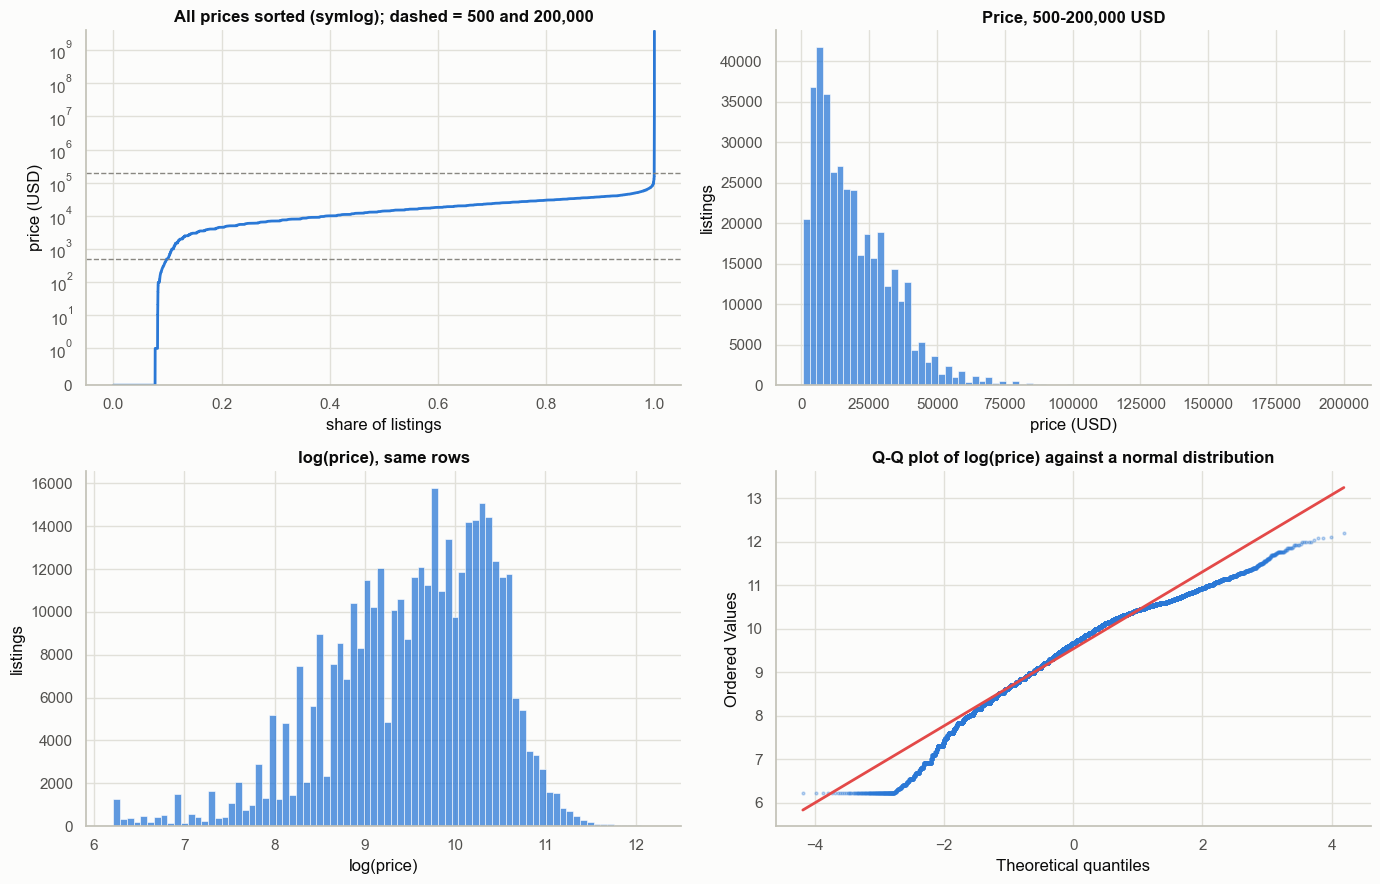

skew in the plotting view: raw 1.68 | log -0.72


In [19]:
#exploring the price visualy
y = df[TARGET]
print(f"zeros: {(y == 0).sum():,} | below {P_LO}: {(y < P_LO).sum():,} | above {P_HI:,}: {(y > P_HI).sum():,}")
print("most common prices:", y.value_counts().head(8).to_dict())

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
ys = np.sort(y.values)
ax[0, 0].plot(np.linspace(0, 1, len(ys)), ys, color=BLUE, lw=2)
for b in (P_LO, P_HI):
    ax[0, 0].axhline(b, color=GREY, ls="--", lw=1)
#symlog is symmetric log to divide the price into understandable sections
ax[0, 0].set_yscale("symlog", linthresh=1)
ax[0, 0].set_ylim(bottom=0)
ax[0, 0].set(title="All prices sorted (symlog); dashed = 500 and 200,000", xlabel="share of listings", ylabel="price (USD)")

sns.histplot(view[TARGET], bins=80, color=BLUE, ax=ax[0, 1])
ax[0, 1].set(title=f"Price, {P_LO:,}-{P_HI:,} USD", xlabel="price (USD)", ylabel="listings")

sns.histplot(view["log_price"], bins=80, color=BLUE, ax=ax[1, 0])
ax[1, 0].set(title="log(price), same rows", xlabel="log(price)", ylabel="listings")

stats.probplot(view["log_price"].sample(50_000, random_state=SEED), plot=ax[1, 1])
pts, fit = ax[1, 1].get_lines()
pts.set(color=BLUE, markersize=2, alpha=.3); fit.set(color=RED, lw=2)
ax[1, 1].set(title="Q-Q plot of log(price) against a normal distribution")
plt.tight_layout(); plt.show()

print(f"skew in the plotting view: raw {stats.skew(view[TARGET]):.2f} | log {stats.skew(view['log_price']):.2f}")

In [20]:
target_insights = {
    'zeros' : ['32,895 rows (7.7%) are exactly 0, by far the most common price, followed by dealer-style prices such as 6,995 and 7,995',
               'a car listed for 0 is not a real price, so these look like placeholders'],
    'tails' : ['the sorted prices form a flat line in the middle and shoot up at both ends: 42,094 rows below 500 and 124 above 200,000 (up to 3.7 billion)',
               'keeping 500-200,000 still leaves 384,662 rows (90.1%)'],
    'shape' : ['within 500-200,000 the prices are right-skewed (skew 1.68); after taking the log the skew drops to -0.72',
               'the log scale looks much closer to a bell curve, so log(price) may suit the model better',
               'the Q-Q plot bends at the bottom because of a small heap of very cheap listings (500-1,100), so the lower limit may need to be higher'],
}

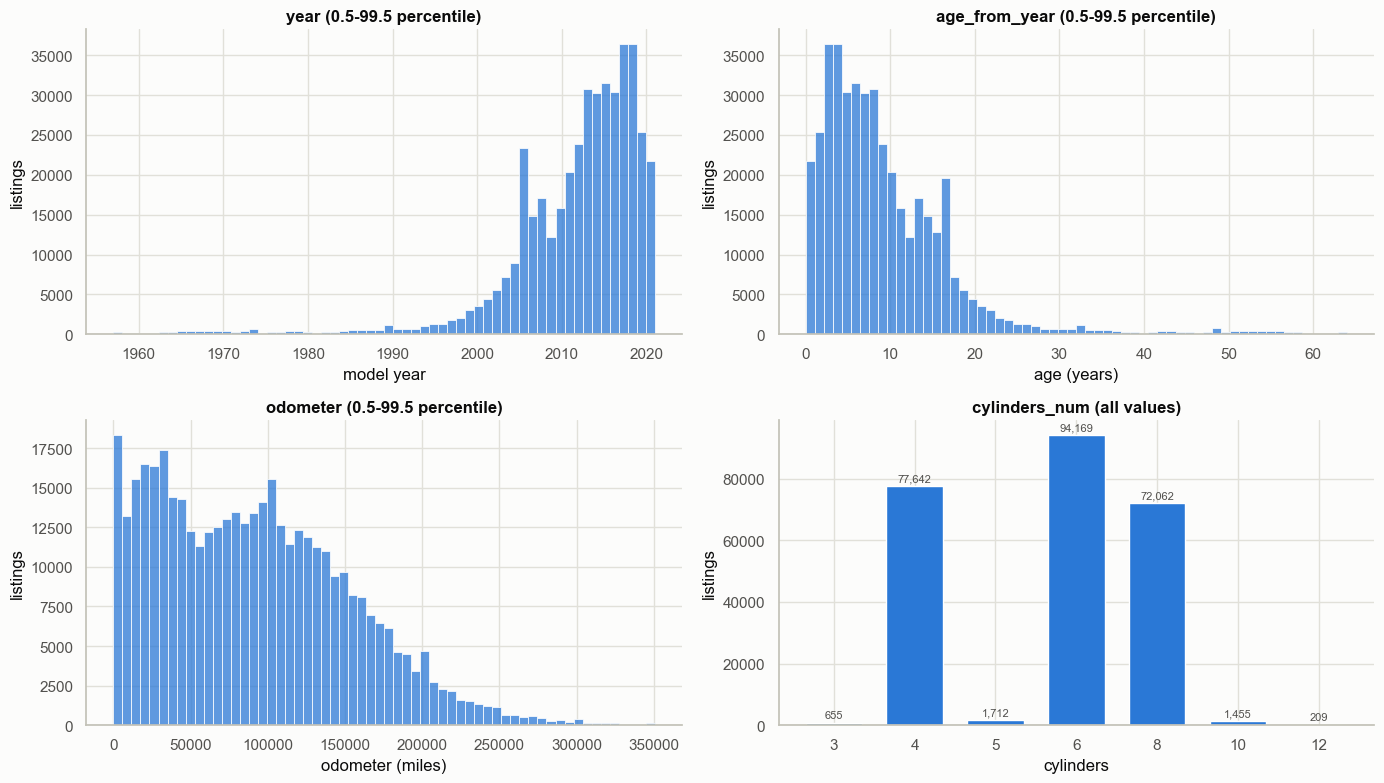

,skew,skew_shown,zeros_%,mode
col,,,,
year,-3.58,-2.65,0.00,"2,017.00"
age_from_year,3.58,2.65,0.56,4.00
odometer,38.04,0.61,0.46,"100,000.00"
cylinders_num,0.13,0.13,0.00,6.00


In [21]:
#exploring car age visualy
hist_cols = {"year": "model year", "age_from_year": "age (years)", "odometer": "odometer (miles)", "cylinders_num": "cylinders"}
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
rows = []
for ax, (c, label) in zip(axes.ravel(), hist_cols.items()):
    s = df[c].dropna()
    if s.nunique() <= 15:                                   
        vc = s.value_counts().sort_index()
        bars = ax.bar(vc.index.astype(int).astype(str), vc.values, color=BLUE, width=.7)
        ax.bar_label(bars, labels=[f"{v:,}" for v in vc.values], fontsize=8, color="#52514e", padding=2)
        ax.set(title=f"{c} (all values)", xlabel=label, ylabel="listings")
    else:                                                   
        s = s[s.between(*s.quantile([.005, .995]))]
        sns.histplot(s, bins=60, color=BLUE, ax=ax)
        ax.set(title=f"{c} (0.5-99.5 percentile)", xlabel=label, ylabel="listings")
    rows.append({"col": c, "skew": stats.skew(df[c].dropna()), "skew_shown": stats.skew(s),
                 "zeros_%": (df[c] == 0).mean() * 100, "mode": s.mode().iat[0]})
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("col")

In [22]:
histogram_insights = {
    'year / age_from_year' : ['year is skewed to the left (-3.58) and age is its mirror (+3.58); most cars are from around 2017',
                              'a long tail of old cars stretches back several decades'],
    'odometer' : ['the skew is 38.0 on all values but only 0.61 once the extreme 0.5% at each end is removed',
                  'the bulk of the data is fairly normal and a few impossible values cause the skew',
                  'the most common value is exactly 100,000, which suggests sellers often type round numbers'],
    'cylinders_num' : ['6 (94,169), 4 (77,642) and 8 (72,062) cylinders make up almost all values; 5, 10, 3 and 12 are rare (1,712 / 1,455 / 655 / 209)',
                      'the shape is almost symmetric (skew 0.13), so it could be used as a number or as a category'],
}

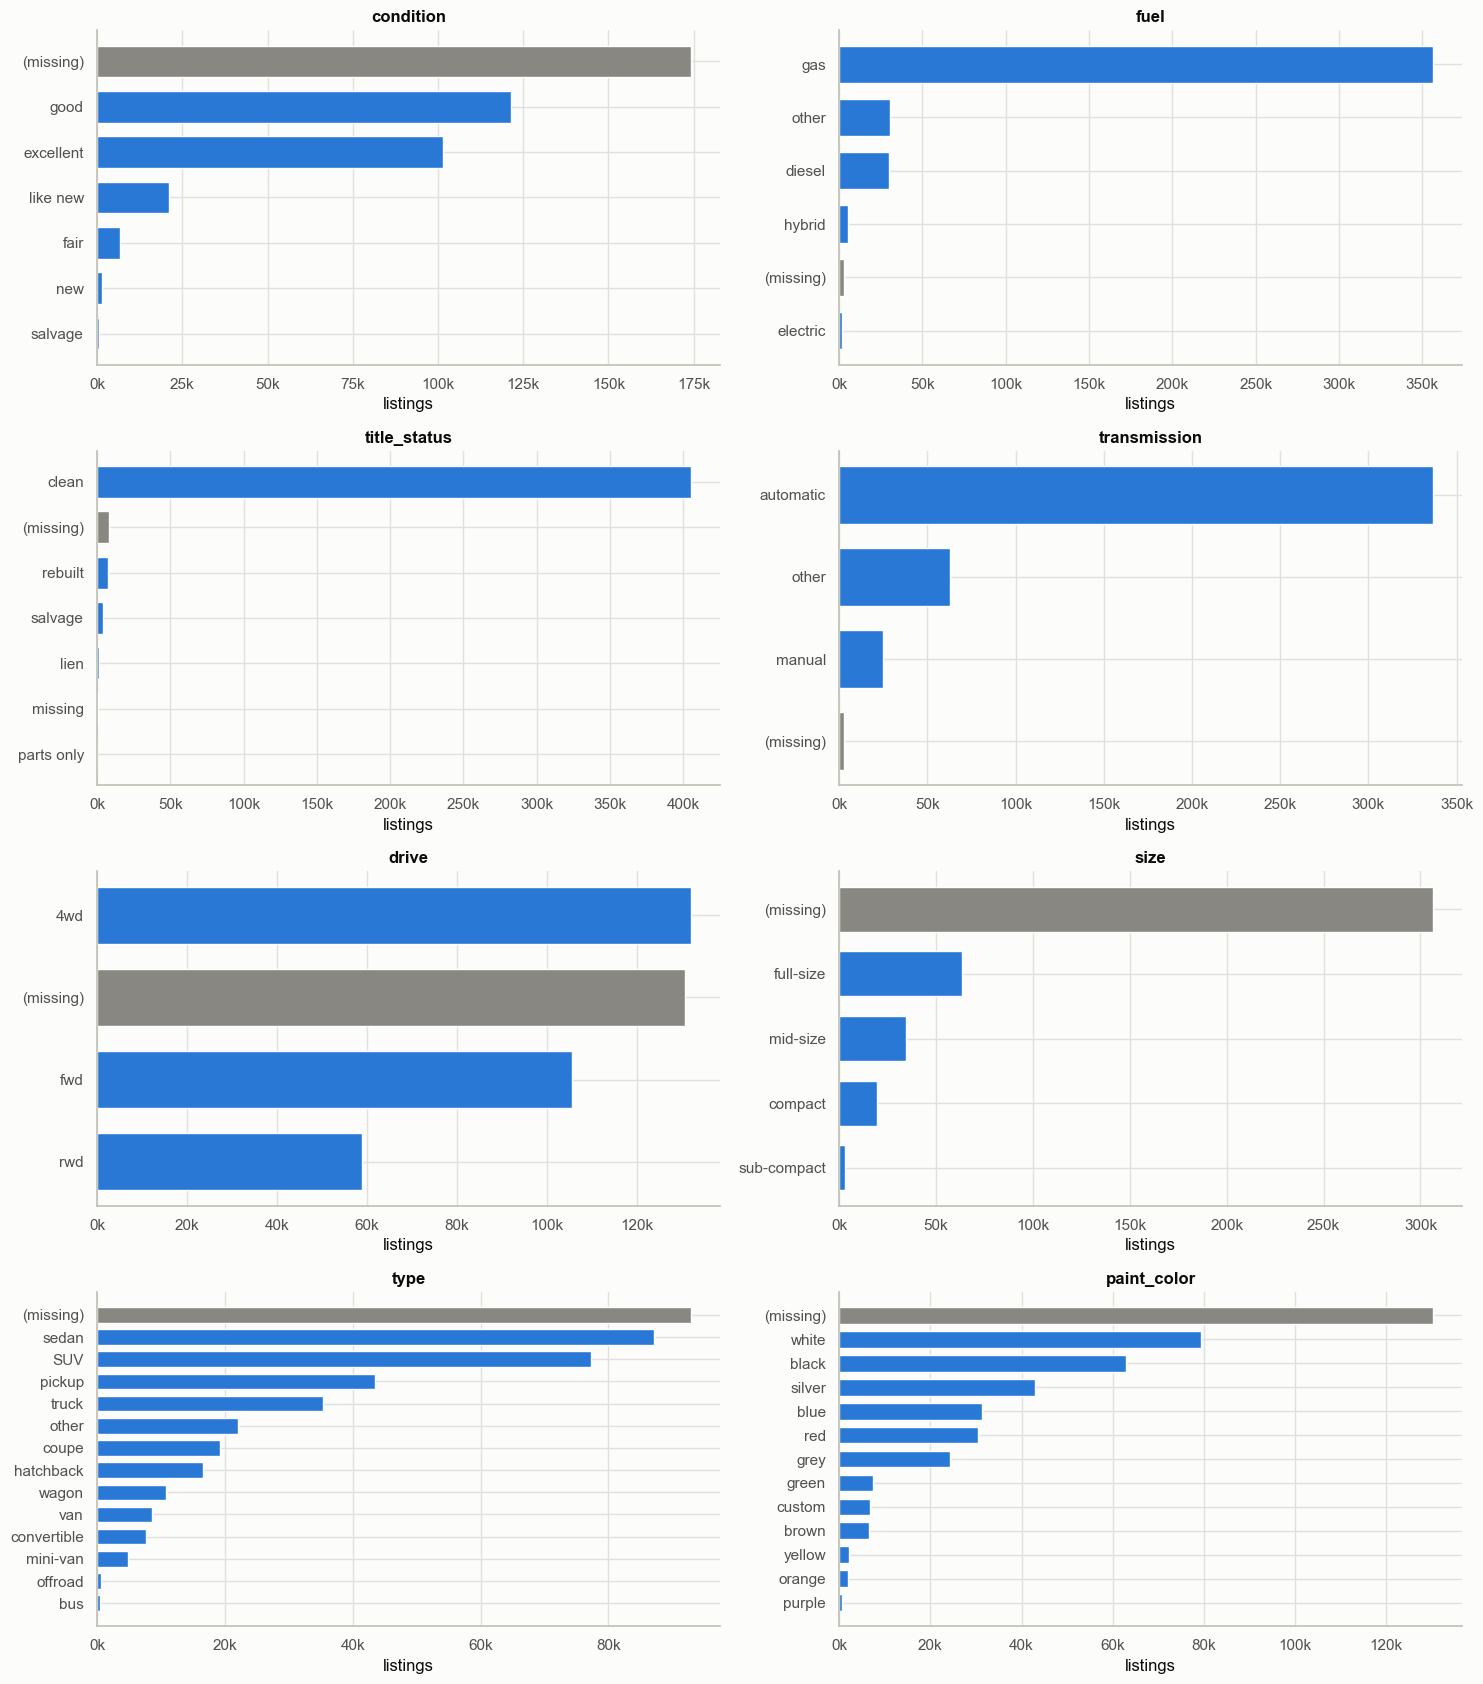

In [23]:
#exploring other features
fig, axes = plt.subplots(4, 2, figsize=(15, 17))
for ax, c in zip(axes.ravel(), cat_low):
    vc = df[c].fillna(MISSING).value_counts().head(15).sort_values()
    ax.barh(vc.index.astype(str), vc.values, color=[GREY if i == MISSING else BLUE for i in vc.index], height=.7)
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
    ax.set(title=c, xlabel="listings", ylabel="")
for ax in axes.ravel()[len(cat_low):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [24]:
categorical_insights = {
    'missing as a level' : ['missing is the largest bar for condition (174,104), size (306,361) and paint_color (130,203), and the second largest for drive (130,567)',
                            'dropping rows with gaps would remove most of the data, so missing may be better kept as its own level'],
    'dominant levels' : ['gas (84%), automatic (79%) and clean (95%) dominate fuel, transmission and title_status',
                         'most of the variety sits in the small levels'],
    'type' : ['after missing (92,858), sedan, SUV and pickup are the most common; pickup and truck together make 78,789 rows'],
}

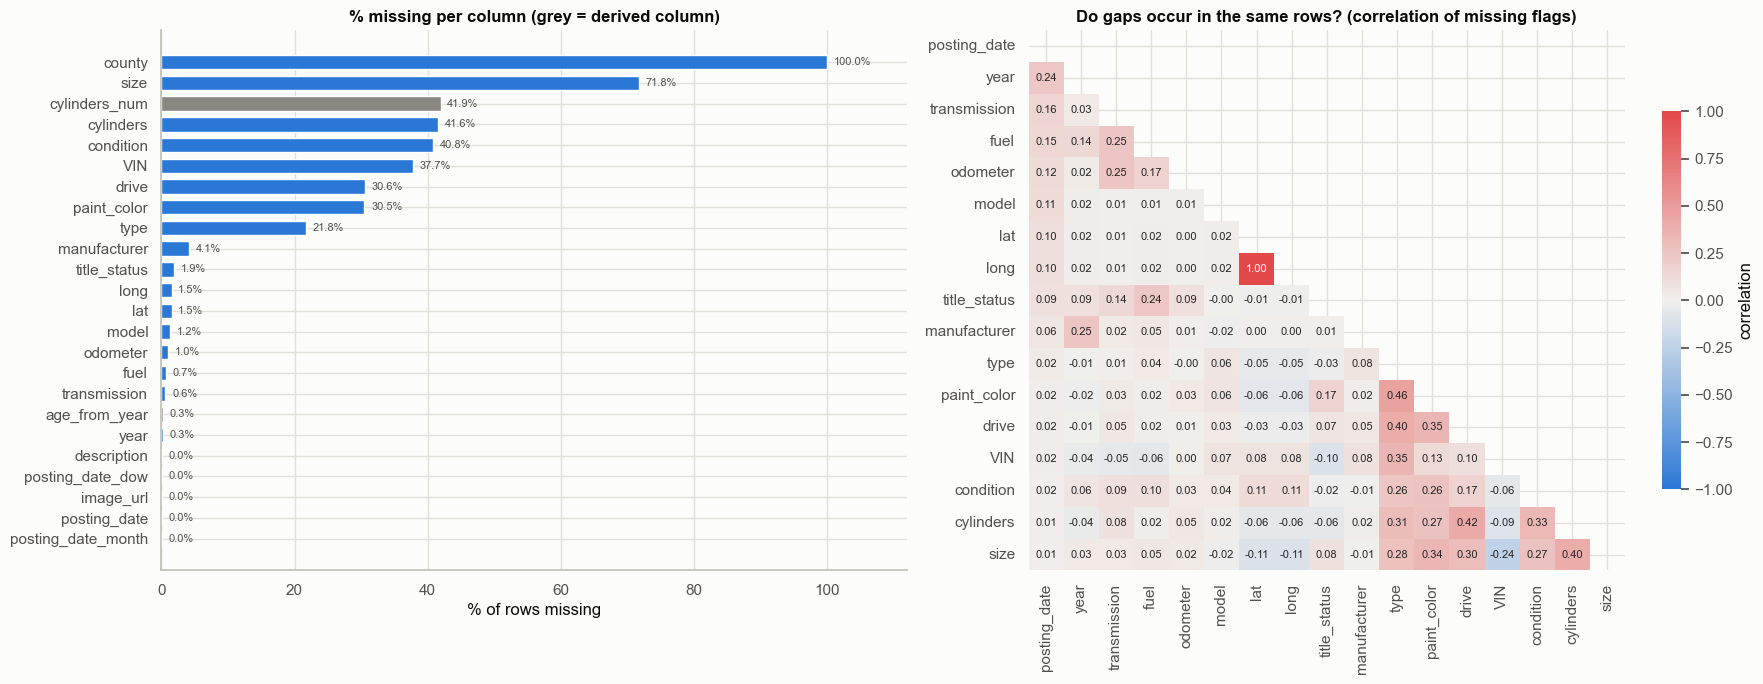

,pct_missing,median_if_present,median_if_missing,ratio
col,,,,
VIN,38.71,"20,000.00","8,995.00",0.45
type,21.62,"16,995.00","10,900.00",0.64
model,1.18,"15,977.00","10,500.00",0.66
posting_date,0.02,"15,900.00","10,825.00",0.68
title_status,1.82,"15,981.00","13,469.50",0.84
paint_color,29.01,"16,500.00","13,988.00",0.85
odometer,0.55,"15,900.00","14,500.00",0.91
manufacturer,4.05,"15,987.00","14,950.00",0.94
transmission,0.47,"15,900.00","14,991.00",0.94


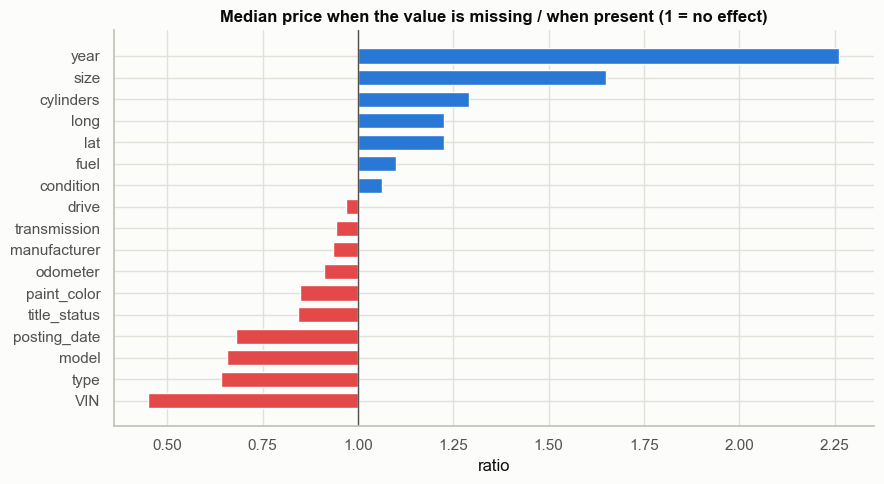

In [25]:
#exploring the missing values and their effect on price
miss = df.isna().mean().mul(100)
miss = miss[miss > 0].sort_values()
partial = [c for c in miss.index if miss[c] < 100 and c in roles and c not in derived
           and roles[c] not in ("url", "free-text")]

fig, ax = plt.subplots(1, 2, figsize=(18, 7))
ax[0].barh(miss.index, miss.values, color=[GREY if c in derived else BLUE for c in miss.index], height=.7)
for i, v in enumerate(miss.values):
    ax[0].text(v + 1, i, f"{v:.1f}%", va="center", fontsize=8, color="#52514e")
ax[0].set(title="% missing per column (grey = derived column)", xlabel="% of rows missing", xlim=(0, 112))

cm_miss = df[partial].isna().corr()
sns.heatmap(cm_miss, mask=np.triu(np.ones_like(cm_miss, dtype=bool)), annot=True, fmt=".2f", cmap=DIV,
            vmin=-1, vmax=1, center=0, ax=ax[1], cbar_kws={"shrink": .7, "label": "correlation"}, annot_kws={"size": 8})
ax[1].set_title("Do gaps occur in the same rows? (correlation of missing flags)")
plt.tight_layout(); plt.show()

rows = []
for c in partial:
    flag = view[c].isna()
    if 0 < flag.mean() < 1:
        med = view.groupby(flag)[TARGET].median()
        rows.append({"col": c, "pct_missing": flag.mean() * 100,
                     "median_if_present": med[False], "median_if_missing": med[True]})
gap_price = pd.DataFrame(rows).set_index("col")
gap_price["ratio"] = gap_price["median_if_missing"] / gap_price["median_if_present"]
gap_price = gap_price.sort_values("ratio")
display(gap_price)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(gap_price.index, gap_price["ratio"] - 1, left=1, height=.7,
        color=[RED if r < 1 else BLUE for r in gap_price["ratio"]])
ax.axvline(1, color="#52514e", lw=1)
ax.set(title="Median price when the value is missing / when present (1 = no effect)", xlabel="ratio")
plt.tight_layout(); plt.show()

In [26]:
missing_insights = {
    'lat / long' : ['their missing flags correlate at 1.00, so they are always missing together'],
    'optional fields' : ['gaps in type, paint_color, drive, cylinders, size and condition tend to appear in the same rows (correlation 0.26-0.46)',
                         'it looks like some sellers skip all the optional fields at once'],
    'VIN' : ['ads without a VIN have a median price of 8,995 against 20,000 for ads with one (ratio 0.45)',
             'dealers usually post a VIN and private sellers usually do not, so whether a VIN is present may itself predict price'],
    'size / cylinders' : ['ads with missing size cost 1.65x more and ads with missing cylinders 1.29x more than the rest',
                          'the gaps seem to come from a particular kind of seller rather than at random'],
    'year' : ['only 0.3% missing, but those rows cost 2.26x more (35,975), which is strange and worth a look'],
    'overall' : ['missing values are not random and carry price information, so filling or dropping them blindly could lose that signal'],
}

age_from_year  Spearman with log(price) (plotting view): -0.669
odometer       Spearman with log(price) (plotting view): -0.597


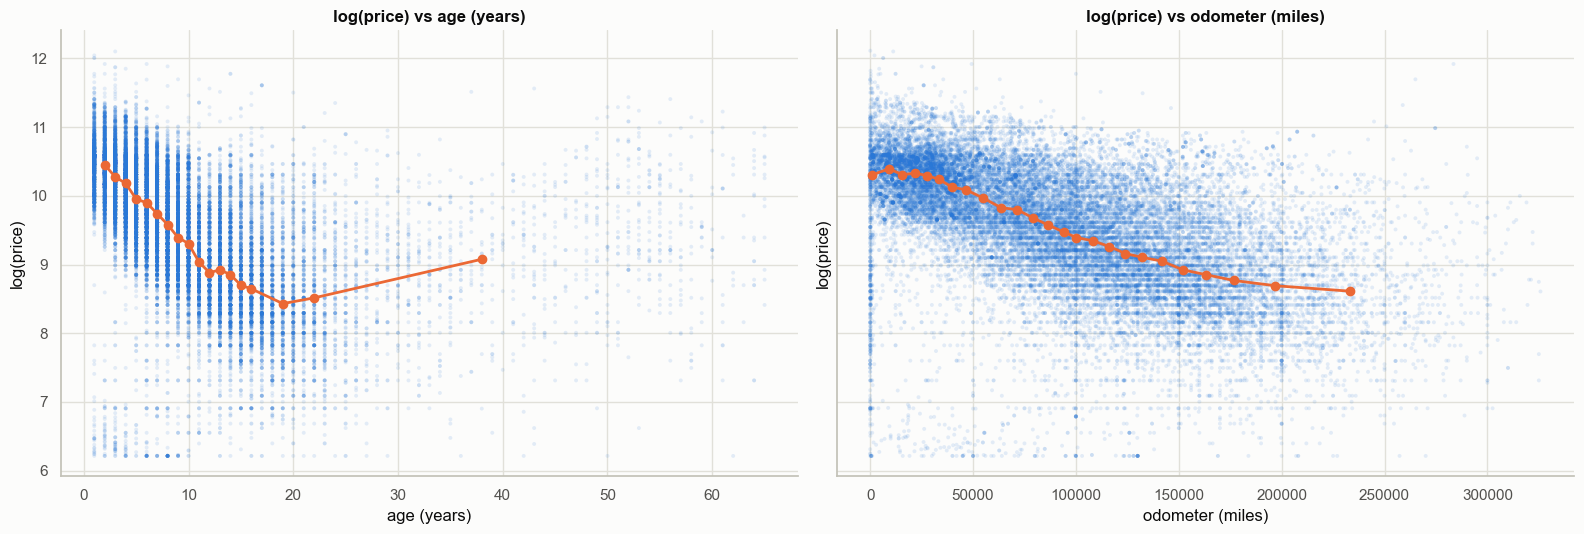

In [27]:
#age and odo corelation with price 

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for ax, c, label in zip(axes, ["age_from_year", "odometer"], ["age (years)", "odometer (miles)"]):
    s = plot_sample[[c, "log_price"]].dropna()
    s = s[s[c].between(*s[c].quantile([.005, .995]))]
    ax.scatter(s[c], s["log_price"], s=8, alpha=.12, color=BLUE, edgecolors="none")
    med = s.groupby(pd.qcut(s[c], 25, duplicates="drop"), observed=True).agg(x=(c, "median"), y=("log_price", "median"))
    ax.plot(med["x"], med["y"], color=ORANGE, lw=2, marker="o", ms=6)
    ax.set(title=f"log(price) vs {label}", xlabel=label, ylabel="log(price)")
    print(f"{c:14s} Spearman with log(price) (plotting view): {view[c].corr(view['log_price'], method='spearman'):+.3f}")
plt.tight_layout(); plt.show()

In [28]:
scatter_insights = {
    'age_from_year' : ['price falls steadily for about the first 20 years (Spearman -0.67), then rises again for older cars, likely classics',
                       'the relationship is not a straight line; a linear model would struggle with it unless age is transformed or capped'],
    'odometer' : ['price falls almost in a straight line (on the log scale) as mileage rises, slowing down past about 150-200k miles (Spearman -0.60)',
                  'a vertical band of cheap cars sits at 0 miles, which suggests 0 often means "not entered" rather than a new car'],
}

condition     median price: {'salvage': 2000, 'fair': 2800, 'excellent': 12000, 'like new': 15000, '(missing)': 16500, 'good': 21000, 'new': 23100}


fuel          median price: {'hybrid': 13000, 'gas': 14000, '(missing)': 17500, 'electric': 25600, 'other': 28000, 'diesel': 32000}


transmission  median price: {'manual': 10000, 'automatic': 13400, '(missing)': 15000, 'other': 28600}


drive         median price: {'fwd': 10700, '(missing)': 15500, 'rwd': 19000, '4wd': 21000}


type          median price: {'mini-van': 7500, '(missing)': 10900, 'sedan': 11500, 'bus': 12000, 'offroad': 12900, 'wagon': 13000, 'hatchback': 14900, 'SUV': 15000, 'convertible': 16000, 'van': 17000, 'coupe': 20600, 'truck': 25600, 'other': 28000, 'pickup': 28300}


title_status  median price: {'parts only': 1700, 'missing': 3000, 'salvage': 7500, 'rebuilt': 10500, '(missing)': 13500, 'clean': 16000, 'lien': 18000}


paint_color   median price: {'green': 9000, 'purple': 10200, 'grey': 11900, 'brown': 12000, 'custom': 13000, 'silver': 13800, '(missing)': 14000, 'blue': 14000, 'yellow': 15000, 'red': 16600, 'orange': 18600, 'black': 19000, 'white': 20000}


size          median price: {'compact': 9000, 'sub-compact': 9000, 'mid-size': 9300, 'full-size': 13000, '(missing)': 18000}


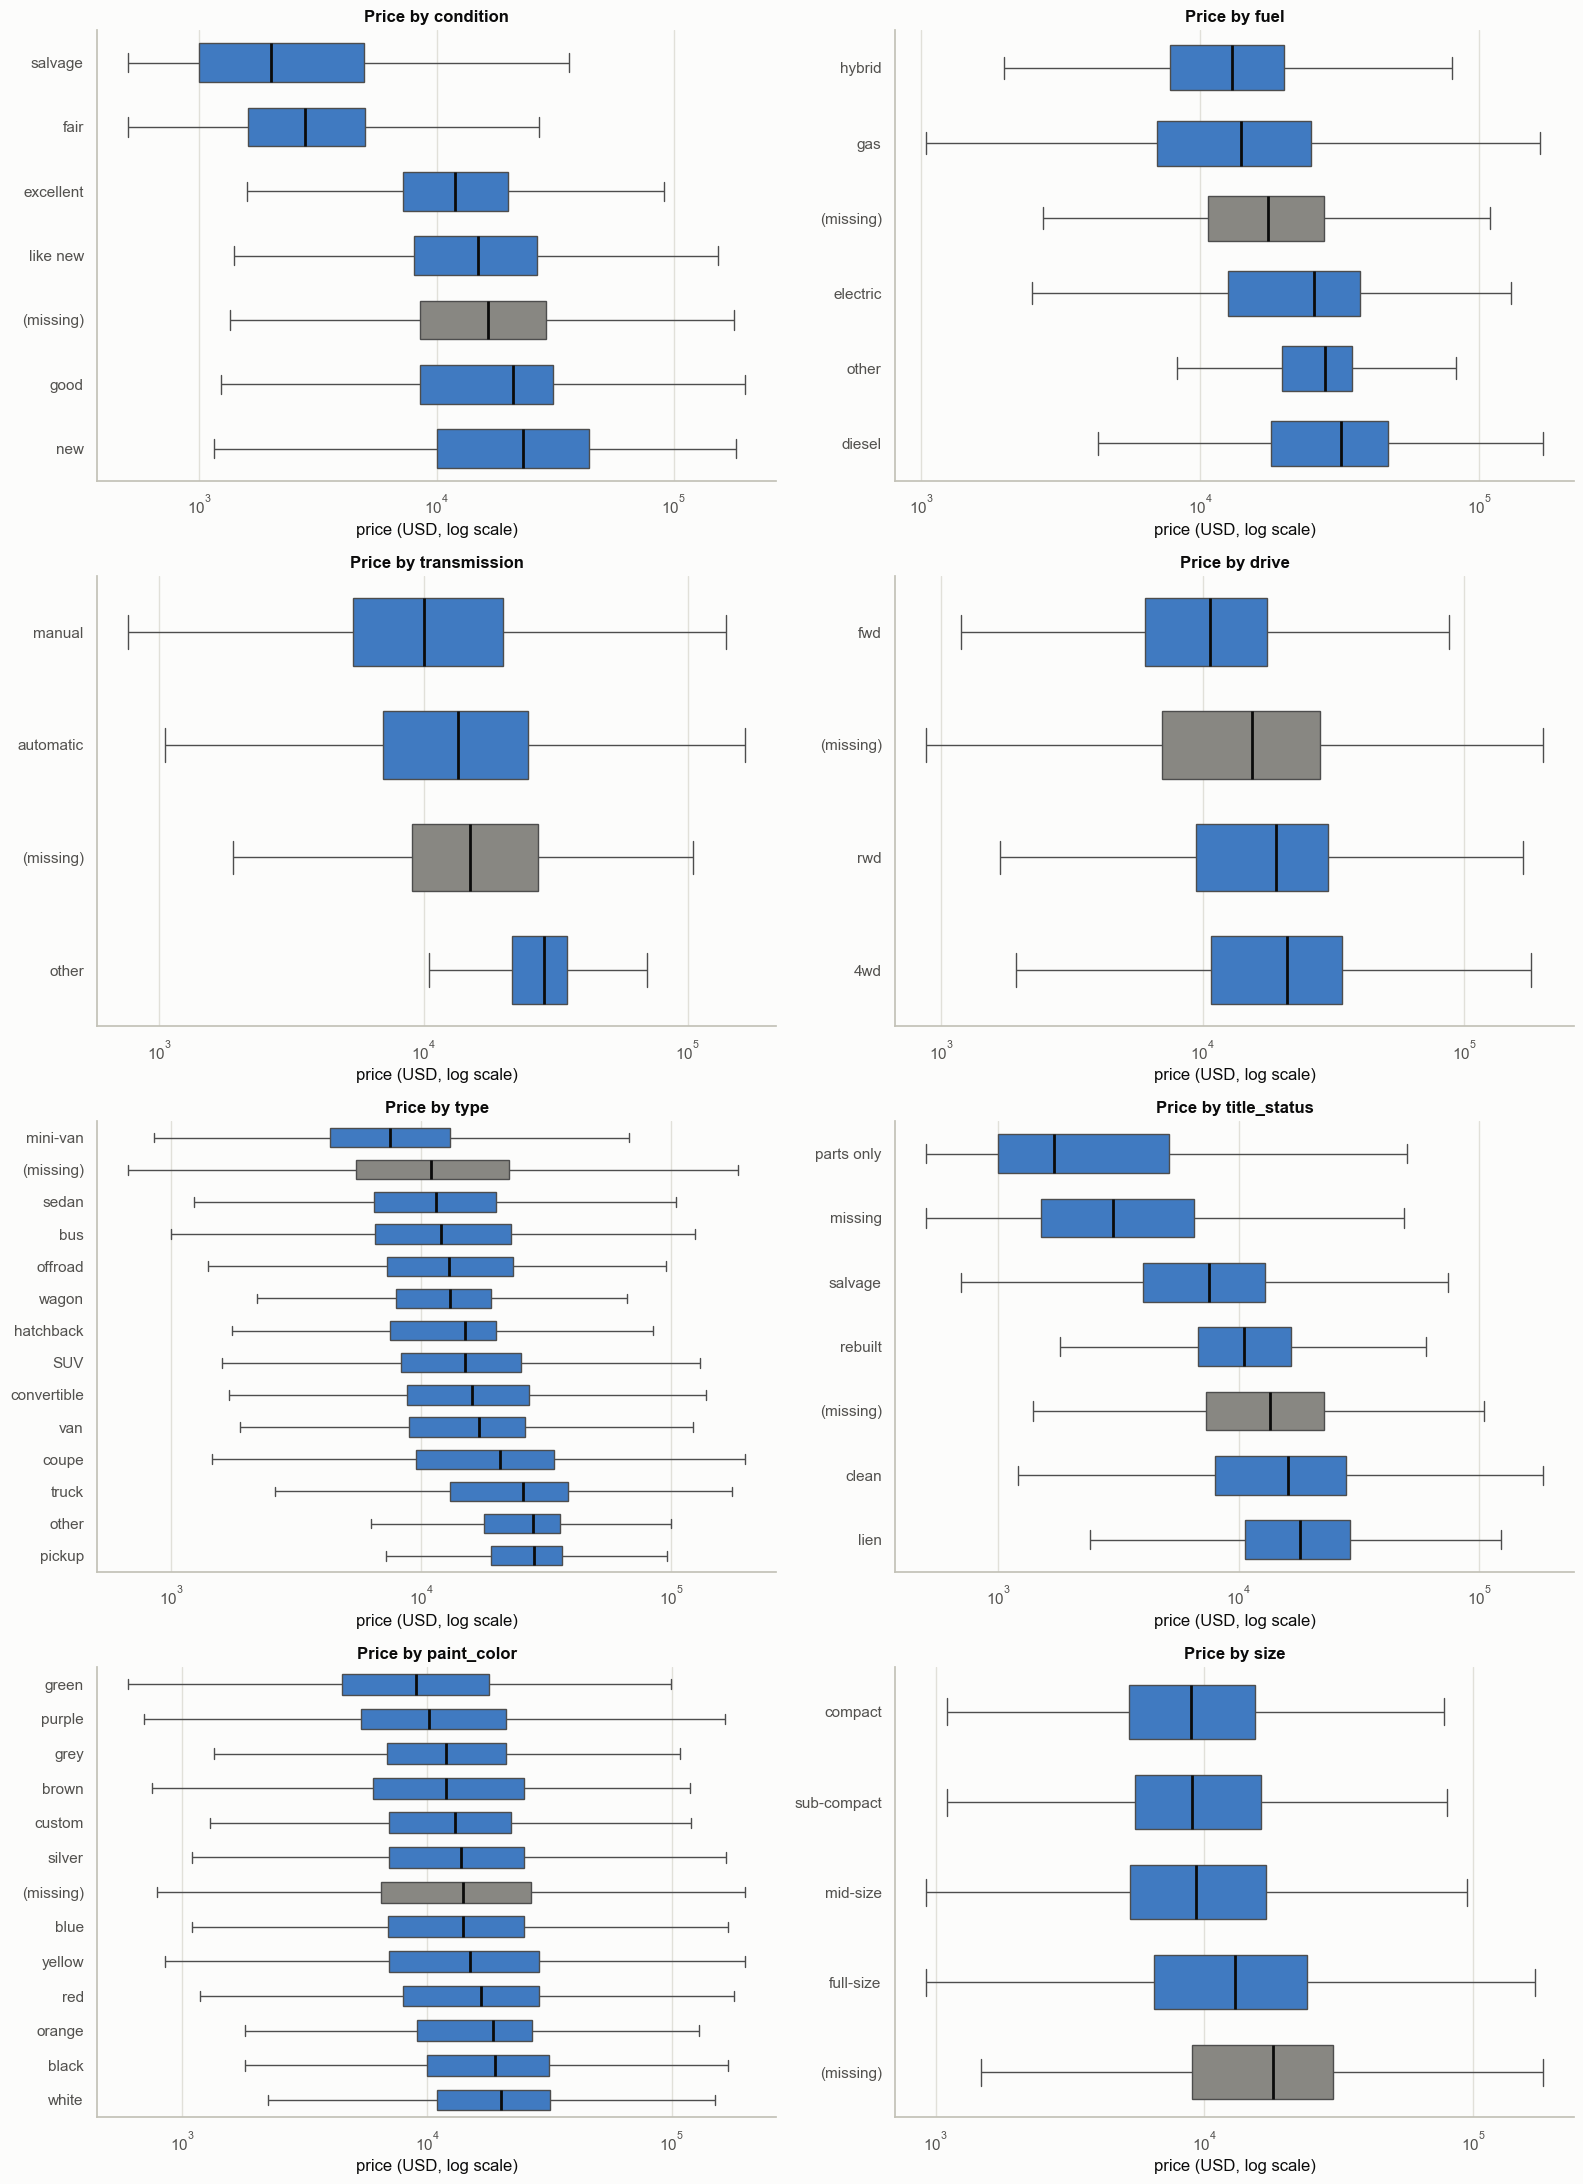

In [29]:
#corelation of other non neumerical features with price
box_cols = ["condition", "fuel", "transmission", "drive", "type", "title_status", "paint_color", "size"]
fig, axes = plt.subplots(4, 2, figsize=(16, 22))
for ax, c in zip(axes.ravel(), box_cols):
    d = view[[c, TARGET, "log_price"]].assign(**{c: view[c].fillna(MISSING)})
    order = d.groupby(c)["log_price"].median().sort_values().index
    sns.boxplot(data=d, y=c, x=TARGET, order=order, hue=c, legend=False, log_scale=True,
                palette={lv: GREY if lv == MISSING else BLUE for lv in order},
                showfliers=False, width=.6, ax=ax, medianprops={"color": "#0b0b0b", "lw": 2})
    ax.set(title=f"Price by {c}", xlabel="price (USD, log scale)", ylabel="")
    print(f"{c:13s} median price:", d.groupby(c)[TARGET].median().loc[order].round(-2).astype(int).to_dict())
plt.tight_layout(); plt.show()

In [30]:
boxplot_insights = {
    'condition' : ['salvage (2,000) and fair (2,800) are far cheaper than the rest',
                   'surprisingly, "good" (21,000) sells for more than "excellent" (12,000) and "like new" (15,000)',
                   'the labels do not follow a clear order, so treating them as a ranked scale could mislead a model'],
    'fuel' : ['diesel (32,000) and "other" (28,000) are the most expensive, while hybrid (13,000) and gas (14,000) are similar',
              'it is odd that "other" costs about twice as much as gas'],
    'transmission' : ['"other" (28,600) costs about twice as much as automatic (13,400), and manual is the cheapest (10,000)',
                      'such a high price for an unclear level is suspicious'],
    'drive' : ['fwd (10,700) < rwd (19,000) < 4wd (21,000): a clear price step between drive types'],
    'type' : ['pickup (28,300), other (28,000) and truck (25,600) are the most expensive, mini-van (7,500) the cheapest',
              'pickup and truck have very similar prices and may be the same thing under two names'],
    'title_status' : ['parts only (1,700), missing (3,000), salvage (7,500) and rebuilt (10,500) are far below clean (16,000)',
                      'these groups are small but have a big effect on price',
                      'the "missing" title behaves like a damaged title rather than an unknown value'],
    'paint_color' : ['white (20,000) and black (19,000) cost about twice as much as green (9,000)',
                     'this may come from body type (e.g. white work trucks) rather than the colour itself'],
    'size' : ['the real sizes are close to each other (9,000-13,000) while missing size sits at 18,000',
              'the fact that size is missing seems to matter more than the size itself'],
}

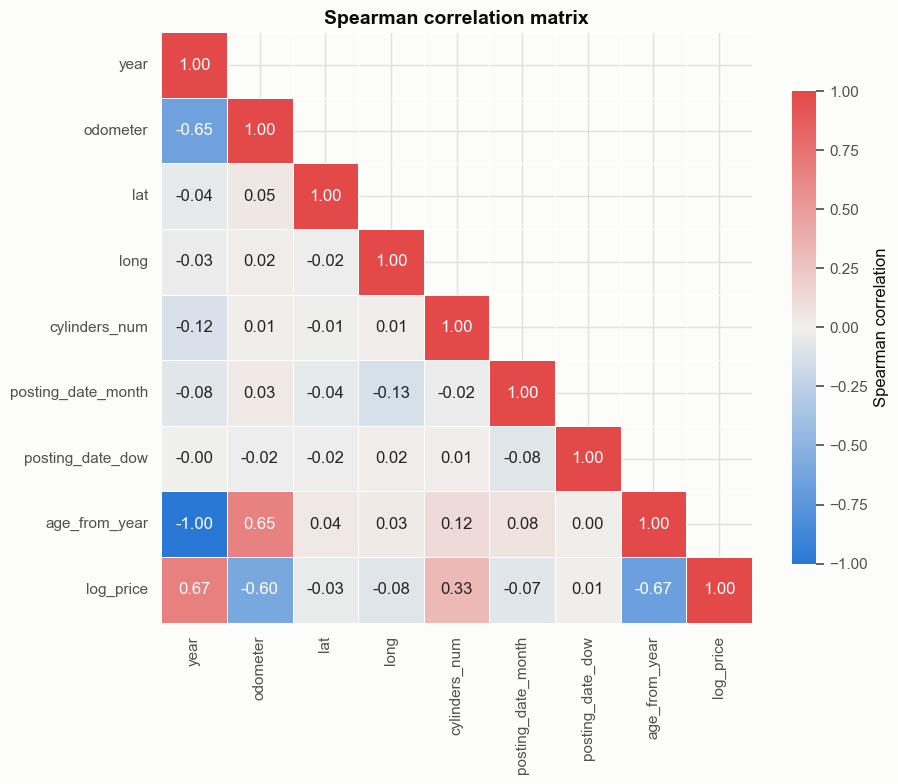

strongly related pairs (|r| > 0.8):
 year  age_from_year   -1.00
dtype: float64

correlation with log(price):
 age_from_year        -0.67
odometer             -0.60
long                 -0.08
posting_date_month   -0.07
lat                  -0.03
posting_date_dow      0.01
cylinders_num         0.33
year                  0.67
Name: log_price, dtype: float64


In [31]:
#correlation between the numeric features and log(price)
# (Spearman: rank-based, robust to outliers)
cm = view[num_feats + ["log_price"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, mask=np.triu(np.ones_like(cm, dtype=bool), 1), annot=True, fmt=".2f", cmap=DIV, vmin=-1, vmax=1,
            center=0, square=True, linewidths=.5, cbar_kws={"shrink": .8, "label": "Spearman correlation"}, ax=ax)
ax.set_title("Spearman correlation matrix", fontsize=14)
plt.tight_layout(); plt.show()

pairs = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack()
print("strongly related pairs (|r| > 0.8):\n", pairs[pairs.abs() > 0.8].round(3))
print("\ncorrelation with log(price):\n", cm["log_price"].drop("log_price").sort_values().round(3))

In [32]:
correlation_insights = {
    'year / age_from_year' : ['correlation -1.00, so they hold exactly the same information and one of them is enough'],
    'with log(price)' : ['age (-0.67), odometer (-0.60) and cylinders_num (+0.33) are the only numeric features clearly linked to price',
                         'longitude (-0.08), posting month (-0.07), latitude (-0.03) and weekday (+0.01) show almost no link to price'],
}

,eta2,levels,n
model,0.55,"1,778.00","297,165.00"
type,0.14,14.00,"384,662.00"
transmission,0.12,4.00,"384,662.00"
manufacturer,0.11,40.00,"384,627.00"
fuel,0.09,6.00,"384,662.00"
cylinders,0.08,9.00,"384,662.00"
drive,0.08,4.00,"384,662.00"
region,0.06,399.00,"384,605.00"
condition,0.06,7.00,"384,662.00"
size,0.05,5.00,"384,662.00"


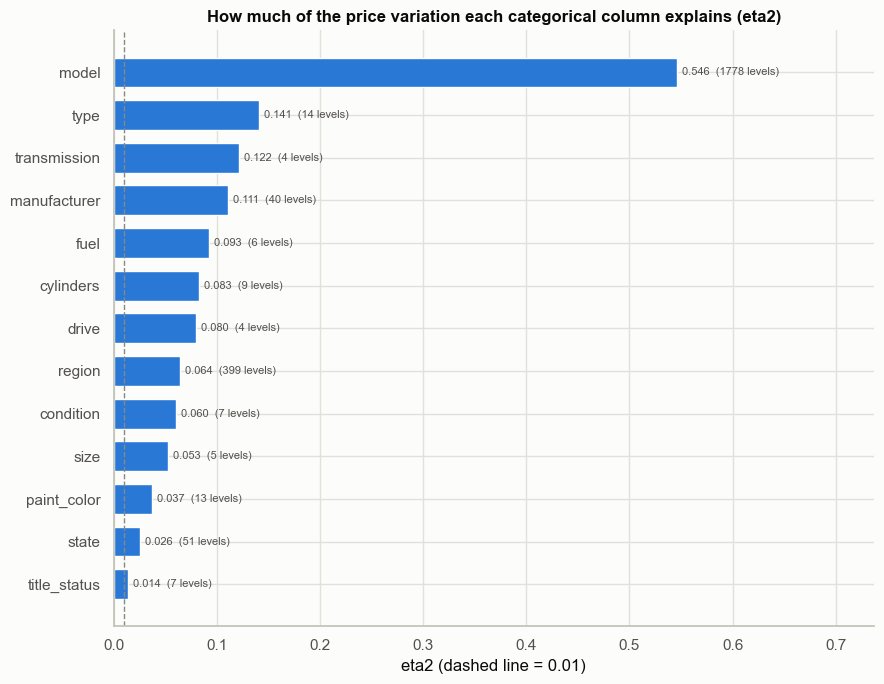

regions that sit in one state: 94.8%


In [33]:
#finding out the feature that corelates with the price best
#works by grouping the data into levels to not be affected by outliers
#eta2 is the indicator, levels are the number of groups created to find the corelation
def kruskal_eta(frame, col, y="log_price", min_n=30):
    d = frame[[col, y]].dropna()
    counts = d[col].value_counts()
    d = d[d[col].isin(counts[counts >= min_n].index)]          
    groups = [g[y].values for _, g in d.groupby(col)]
    if len(groups) < 2:
        return pd.Series({"H": np.nan, "p": np.nan, "eta2": np.nan, "levels": len(groups), "n": len(d)})
    H, pval = stats.kruskal(*groups)
    k, n = len(groups), len(d)
    return pd.Series({"H": H, "p": pval, "eta2": (H - k + 1) / (n - k), "levels": k, "n": n})

eta_cols = cat_low + cat_high + text_num + disc_cols
eta_frame = view[["log_price"]].copy()
for c in eta_cols:                                           
    eta_frame[c] = view[c].astype("object").where(view[c].notna(), MISSING).astype(str)

ranking = pd.DataFrame({c: kruskal_eta(eta_frame, c) for c in eta_cols}).T.sort_values("eta2")
display(ranking[["eta2", "levels", "n"]].sort_values("eta2", ascending=False))

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(ranking.index, ranking["eta2"], color=BLUE, height=.7)
for i, (e, k) in enumerate(zip(ranking["eta2"], ranking["levels"])):
    ax.text(e + .005, i, f"{e:.3f}  ({int(k)} levels)", va="center", fontsize=8, color="#52514e")
ax.axvline(.01, color=GREY, ls="--", lw=1)
ax.set(title="How much of the price variation each categorical column explains (eta2)",
       xlabel="eta2 (dashed line = 0.01)", xlim=(0, ranking["eta2"].max() * 1.35))
plt.tight_layout(); plt.show()

print("regions that sit in one state:", f"{(df.groupby('region')['state'].nunique() == 1).mean():.1%}")

In [34]:
eta2_insights = {
    'strongest' : ['model has by far the highest score (0.546), but it is split into 1,778 levels, which inflates eta2',
                   'among columns with few levels, type (0.141, 14 levels), transmission (0.122, 4) and manufacturer (0.111, 40) explain the most'],
    'middle' : ['fuel (0.093), cylinders (0.083), drive (0.080) and condition (0.060) each explain 6-9% of the price differences with under 10 levels'],
    'weak' : ['size (0.053), paint_color (0.037), state (0.026) and title_status (0.014) are weaker, but all still pass the 0.01 line'],
    'title_status' : ['the lowest score, because 95% of cars are "clean"; the damaged titles are priced very differently but are too few to move the overall score'],
    'transmission' : ['scores surprisingly high for only 4 levels; most of it likely comes from the expensive "other" level, which is worth a closer look'],
    'region vs state' : ['region scores higher than state (0.064 vs 0.026), but with 399 levels against 51',
                        '94.8% of regions sit inside one state, so region mostly repeats state in more detail'],
    'overall' : ['no categorical column falls below 0.01, so none can be dropped on this score alone'],
}

In [35]:
bussiness_understanding={
    'fact1' : 'there should not be any elctric, hybrid manual cars',
    'fact2' : 'carvana is a popular used car dealership in the USA',
}

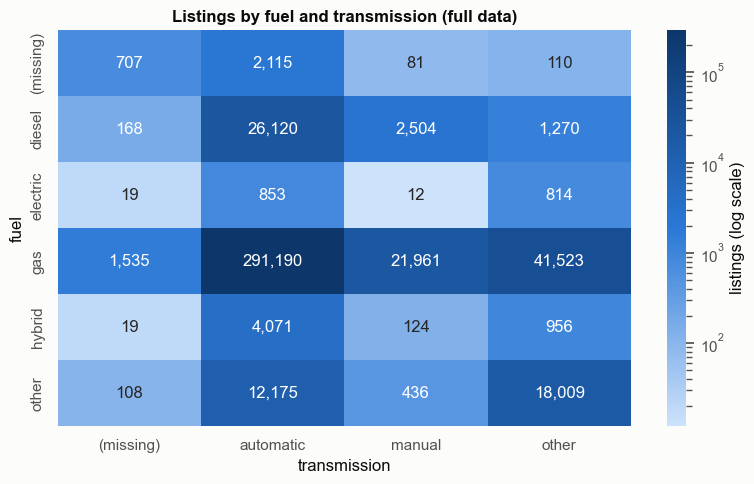


fuel (plotting view):


,n,carvana_share,median_price
fuel,,,
hybrid,4758,24.50,"12,995.00"
gas,322214,13.30,"13,990.00"
(missing),2594,0.00,"17,479.00"
electric,1599,44.40,"25,590.00"
other,27471,66.60,"27,990.00"
diesel,26026,2.80,"31,999.00"



transmission (plotting view):


,n,carvana_share,median_price
transmission,,,
manual,23328,1.30,"10,000.00"
automatic,298753,2.70,"13,445.00"
(missing),1816,0.10,"14,991.00"
other,60765,91.10,"28,590.00"


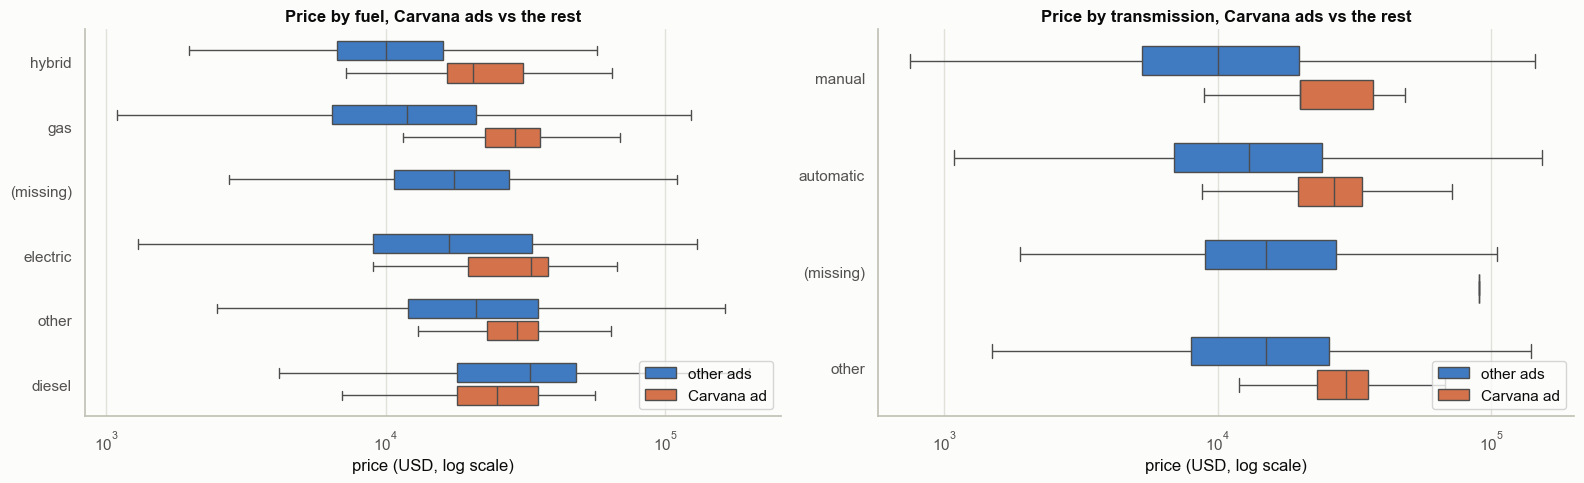

fuel='other' without Carvana: 9,174 rows, median price 20,990
top types : {'pickup': 2851, 'other': 1385, 'sedan': 1054, 'SUV': 1044, 'van': 447, 'hatchback': 389}
top models: {'f-150': 401, 'silverado': 297, 'f-250': 233, 'f-350': 159, 'silverado 1500': 140, 'tahoe': 132, 'sierra': 123, '1500': 111}


transmission='automatic': ads mentioning CVT 2.5%, dual clutch 0.1%


transmission='other': ads mentioning CVT 1.0%, dual clutch 0.0%


In [36]:
# Why do fuel and transmission have an 'other' level? Check whether it marks dealer ads
view["is_carvana"] = view["description"].str.contains("carvana", case=False, na=False)

ct = pd.crosstab(df["fuel"].fillna(MISSING), df["transmission"].fillna(MISSING))
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(ct, annot=True, fmt=",d", cmap=SEQ, norm=mpl.colors.LogNorm(), cbar_kws={"label": "listings (log scale)"}, ax=ax)
ax.set(title="Listings by fuel and transmission (full data)", xlabel="transmission", ylabel="fuel")
plt.tight_layout(); plt.show()

for c in ["fuel", "transmission"]:
    t = (view.assign(**{c: view[c].fillna(MISSING)})
             .groupby(c).agg(n=(TARGET, "size"), carvana_share=("is_carvana", "mean"), median_price=(TARGET, "median"))
             .sort_values("median_price"))
    t["carvana_share"] = (t["carvana_share"] * 100).round(1)
    print(f"\n{c} (plotting view):"); display(t)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, c in zip(axes, ["fuel", "transmission"]):
    d = view.assign(**{c: view[c].fillna(MISSING), "ad": np.where(view["is_carvana"], "Carvana ad", "other ads")})
    order_c = d.groupby(c)["log_price"].median().sort_values().index
    sns.boxplot(data=d, y=c, x=TARGET, hue="ad", hue_order=["other ads", "Carvana ad"], order=order_c, log_scale=True,
                palette={"other ads": BLUE, "Carvana ad": ORANGE}, showfliers=False, width=.7, gap=.15, ax=ax)
    ax.set(title=f"Price by {c}, Carvana ads vs the rest", xlabel="price (USD, log scale)", ylabel="")
    ax.legend(title="", loc="lower right")
plt.tight_layout(); plt.show()

# What else is in 'other' once Carvana ads are removed?
rest = view[(view["fuel"] == "other") & ~view["is_carvana"]]
print(f"fuel='other' without Carvana: {len(rest):,} rows, median price {rest[TARGET].median():,.0f}")
print("top types :", rest["type"].value_counts().head(6).to_dict())
print("top models:", rest["model"].value_counts().head(8).to_dict())
CVT, DCT = r"\bcvt\b", r"dual clutch|\bdct\b"
for lvl in ["automatic", "other"]:
    txt = view.loc[view["transmission"] == lvl, "description"].fillna("")
    print(f"transmission='{lvl}': ads mentioning CVT {txt.str.contains(CVT, case=False).mean():.1%}, "
          f"dual clutch {txt.str.contains(DCT, case=False).mean():.1%}")

In [37]:
other_level_insights = {
    'transmission "other"' : ['91.1% of the 60,765 "other" ads are Carvana ads, against 2.7% for automatic and 1.3% for manual',
                              'CVT is mentioned less in "other" ads (1.0%) than in automatic ones (2.5%), so "other" is not a special gearbox',
                              'it looks like the way Carvana fills in the field rather than a real transmission type'],
    'fuel "other"' : ['66.6% of the 27,471 "other" ads are Carvana ads; electric is also 44.4% Carvana',
                      'without Carvana, 9,174 rows remain (median 20,990), mostly pickups such as f-150, silverado and f-250, which may be flex-fuel trucks'],
    'dealer effect' : ['Carvana ads cost more than other ads within almost every fuel and transmission level (diesel is the exception)',
                       'the high price of "other" seems to come from who is selling, not from the fuel or gearbox',
                       'a flag marking Carvana ads could capture this effect directly'],
}

eta2 of paint_color (share of log-price variation it explains):
all types   0.04
sedan       0.05
SUV         0.03
pickup      0.03
truck       0.03
dtype: float64


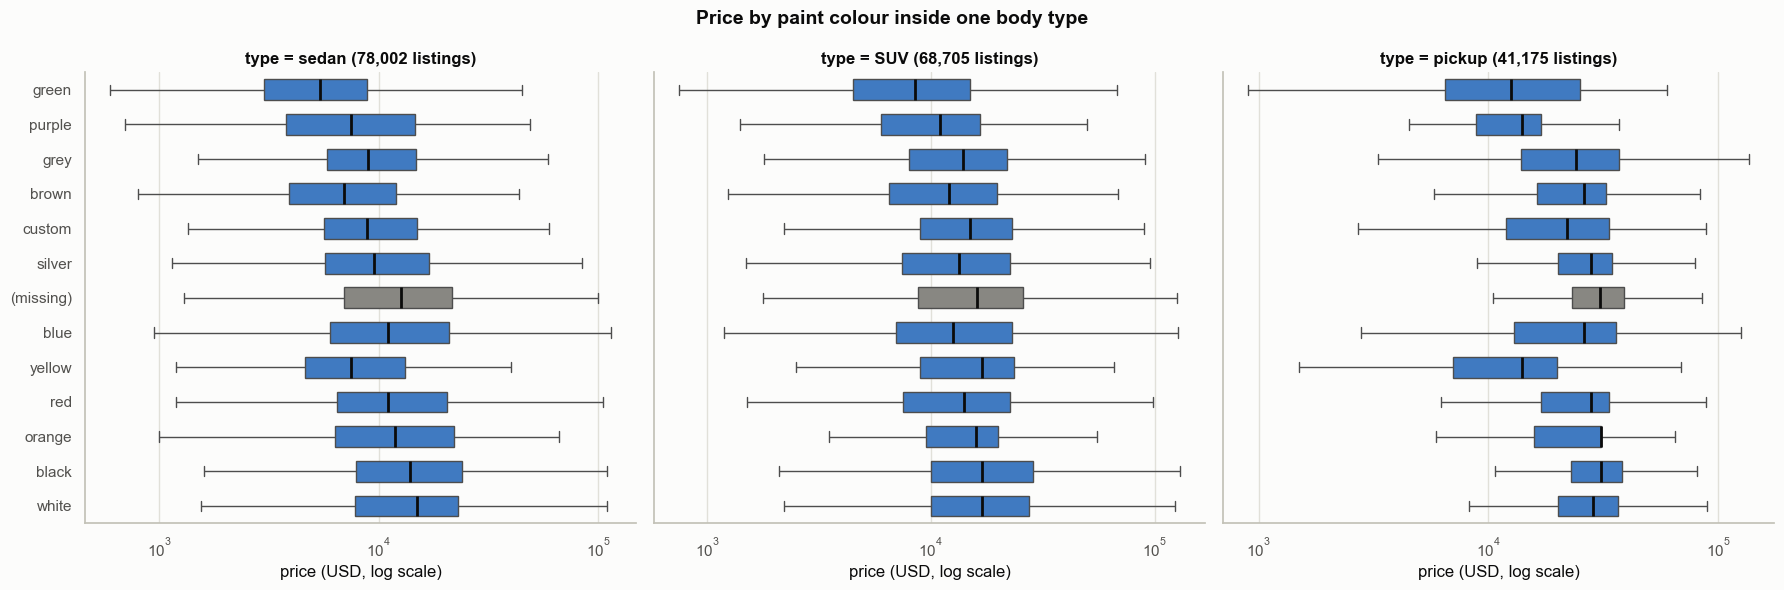

In [38]:
# 3.10 paint_color: does colour matter by itself, or only because colour follows body type (white work trucks)?
paint_eta = {"all types": kruskal_eta(eta_frame, "paint_color")["eta2"]}
for t in ["sedan", "SUV", "pickup", "truck"]:
    paint_eta[t] = kruskal_eta(eta_frame[eta_frame["type"] == t], "paint_color")["eta2"]
print("eta2 of paint_color (share of log-price variation it explains):")
print(pd.Series(paint_eta).round(4))

order = view.assign(p=view["paint_color"].fillna(MISSING)).groupby("p")["log_price"].median().sort_values().index
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, t in zip(axes, ["sedan", "SUV", "pickup"]):
    d = view[view["type"] == t].assign(paint_color=lambda f: f["paint_color"].fillna(MISSING))
    sns.boxplot(data=d, y="paint_color", x=TARGET, order=order, hue="paint_color", legend=False, log_scale=True,
                palette={lv: GREY if lv == MISSING else BLUE for lv in order}, showfliers=False, width=.6, ax=ax,
                medianprops={"color": "#0b0b0b", "lw": 2})
    ax.set(title=f"type = {t} ({len(d):,} listings)", xlabel="price (USD, log scale)", ylabel="")
plt.suptitle("Price by paint colour inside one body type", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

In [39]:
paint_insights = {
    'eta2' : ['paint explains 3.7% of the price variation overall, and 3-5% inside one body type (sedan 0.05; SUV, pickup and truck 0.03)'],
    'within type' : ['inside sedans, white and black cars cost about 3 times as much as green ones (around 15,000 vs 5,000)',
                     'inside pickups the gap is smaller, but green, yellow and purple stay at the bottom'],
    'overall' : ['colour has a small effect of its own, not only through body type, so dropping it would lose some information'],
}

raw text                 29,667 levels | {50: '24.6%', 200: '44.4%', 1000: '68.9%'} of listings covered by the top 50 / 200 / 1000 levels
first word, lowercased    4,437 levels | {50: '47.7%', 200: '82.0%', 1000: '98.0%'} of listings covered by the top 50 / 200 / 1000 levels


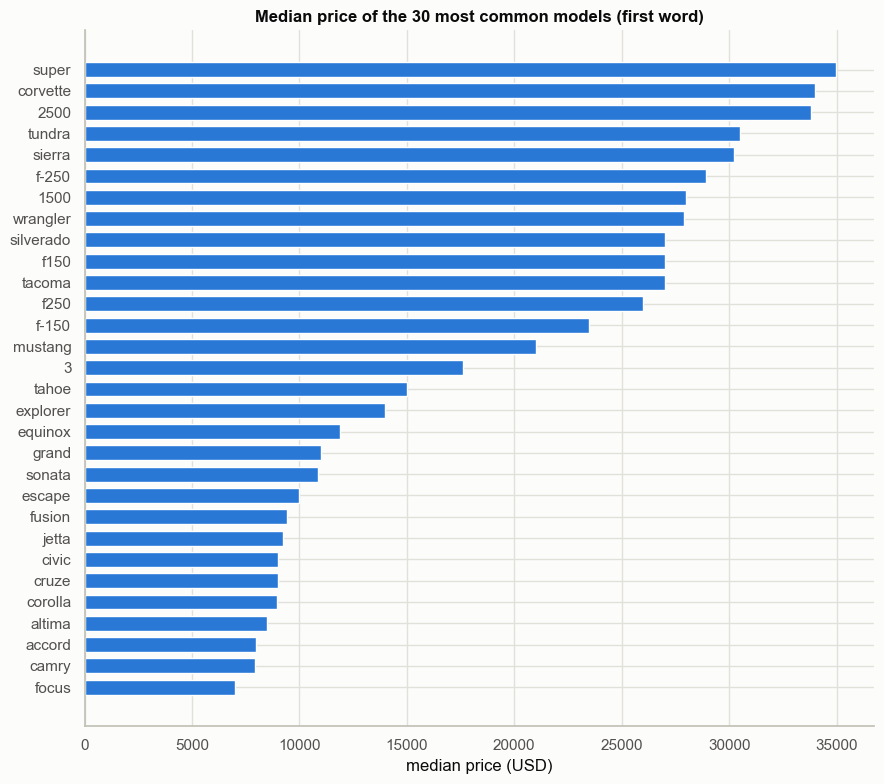

eta2 raw model       : 0.546
eta2 model first word: 0.397
eta2 manufacturer    : 0.111


In [40]:
#exploring the model column
model_raw = df["model"].dropna()
model_first = model_raw.str.lower().str.strip().str.split().str[0]

for s, name in [(model_raw, "raw text"), (model_first, "first word, lowercased")]:
    cum = s.value_counts().cumsum() / len(s) * 100
    print(f"{name:24s} {len(cum):>6,} levels |", {k: f"{cum.iloc[k - 1]:.1f}%" for k in [50, 200, 1000]},
          "of listings covered by the top 50 / 200 / 1000 levels")

view["model_first"] = view["model"].str.lower().str.strip().str.split().str[0]
top_models = (view.groupby("model_first")[TARGET].agg(n="size", median="median")
                  .nlargest(30, "n").sort_values("median"))
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top_models.index, top_models["median"], color=BLUE, height=.7)
ax.set(title="Median price of the 30 most common models (first word)", xlabel="median price (USD)", ylabel="")
plt.tight_layout(); plt.show()

eta_frame["model_first"] = view["model_first"].fillna(MISSING)
print("eta2 raw model       :", round(kruskal_eta(eta_frame, "model")["eta2"], 3))
print("eta2 model first word:", round(kruskal_eta(eta_frame, "model_first")["eta2"], 3))
print("eta2 manufacturer    :", round(kruskal_eta(eta_frame, "manufacturer")["eta2"], 3))

In [41]:
model_insights = {
    'coverage' : ['the top 200 raw models cover only 44.4% of the ads, while the top 200 first words cover 82.0% and the top 1,000 cover 98.0%',
                  'keeping only the first word shrinks the column a lot without losing many ads'],
    'signal' : ['raw model explains 0.546 of the price variation (with 1,778 levels, which inflates it), the first word 0.397 and manufacturer only 0.111',
                'even shortened to its first word, model says much more about price than manufacturer'],
    'messy values' : ['the same model appears under different spellings ("f150" / "f-150", "f250" / "f-250")',
                      'some first words are ambiguous on their own ("1500", "2500", "3", "grand", "super")'],
    'price spread' : ['common models range from about 7,000 (focus) to 35,000 (super duty), with trucks at the top'],
}

,iqr_outliers,robust_z_outliers,outside_plausible,min,p0.1,median,p99.9,max
col,,,,,,,,
price,8177,769,"42,218.00",0.00,0.00,"13,950.00","120,000.00","3,736,928,711.00"
year,15896,7681,"1,346.00","1,900.00","1,932.00","2,013.00","2,021.00","2,022.00"
odometer,4385,1363,"1,386.00",0.00,0.00,"85,548.00","1,111,111.00","10,000,000.00"
lat,6413,63,85.00,-84.12,20.74,39.15,61.59,82.39
long,195,93,106.00,-159.83,-157.97,-88.43,-69.68,173.89
cylinders_num,0,0,NaN,3.00,3.00,6.00,10.00,12.00


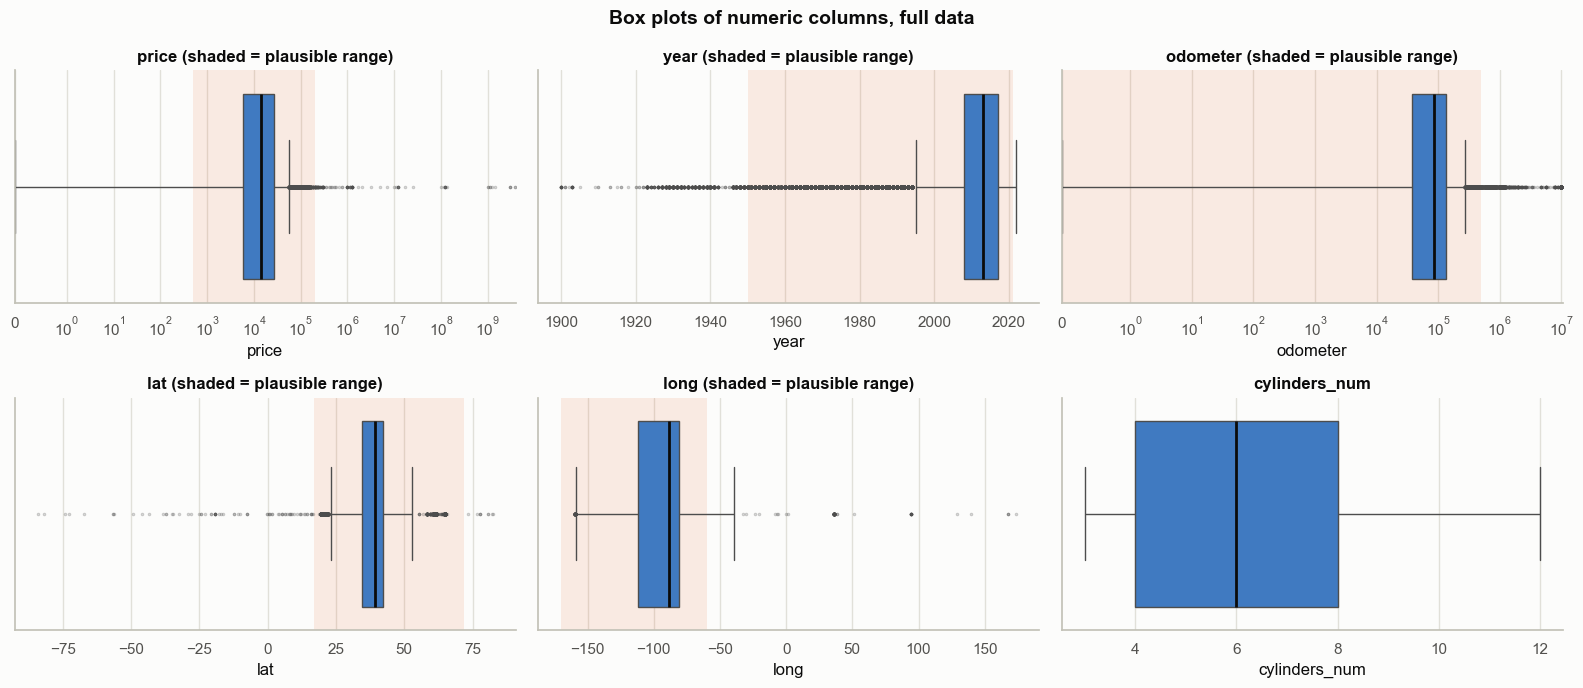

In [42]:
#exploring the outliers
out_cols = [TARGET, "year", "odometer", "lat", "long", "cylinders_num"]
rows = []
for c in out_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    mad = (s - s.median()).abs().median()
    rz = ((s - s.median()).abs() / (1.4826 * mad) > 6).sum() if mad > 0 else 0
    rng = data_dictionary.get(c, {}).get("plausible")
    rows.append({"col": c,
                 "iqr_outliers": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
                 "robust_z_outliers": int(rz),
                 "outside_plausible": int(((s < rng[0]) | (s > rng[1])).sum()) if rng else None,
                 "min": s.min(), "p0.1": s.quantile(.001), "median": s.median(), "p99.9": s.quantile(.999), "max": s.max()})
outlier_report = pd.DataFrame(rows).set_index("col")
display(outlier_report)

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, c in zip(axes.ravel(), out_cols):
    rng = data_dictionary.get(c, {}).get("plausible")
    if rng:
        ax.axvspan(*rng, color=ORANGE, alpha=.12, lw=0)
    sns.boxplot(x=df[c].dropna(), ax=ax, color=BLUE, fliersize=1.5, flierprops={"alpha": .3},
                medianprops={"color": "#0b0b0b", "lw": 2})
    if c in (TARGET, "odometer"):
        ax.set_xscale("symlog", linthresh=1)
        ax.set_xlim(left=0)
    ax.set(title=f"{c}" + (" (shaded = plausible range)" if rng else ""), xlabel=c)
plt.suptitle("Box plots of numeric columns, full data", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

In [43]:
outlier_insights = {
    'price' : ['the IQR rule flags 8,177 rows and the robust z-score 769, both only at the high end',
               'neither catches the 32,895 zeros, while the 500-200,000 range flags 42,218 rows including them',
               'a sensible range fits this problem better than the statistical rules'],
    'year' : ['the IQR rule flags 15,896 rows (roughly every car older than 1995), but most of these are real classic cars',
              'the 1950-2021 range flags only 1,346, which seems more reasonable'],
    'odometer' : ['1,386 rows are above 500k miles; the 99.9th percentile is exactly 1,111,111 and the maximum 10,000,000, both clearly typed placeholders'],
    'lat / long' : ['85 latitudes and 106 longitudes fall outside the plausible range (lat down to -84, long up to 174), likely sign or typing errors'],
    'cylinders_num' : ['no outliers: every value is between 3 and 12'],
}

In [ ]:
final_decisions = {
    'price' : {'action' : 'keep rows priced 500 to the 99.9th percentile drop the rest',
               'reason' : '0 and 1-499 are placeholders (7.7% of ads are exactly 0) and the top 0.1% holds typed values up to 3.7 billion;'
               'a made-up target would teach the model wrong prices'},
    'year' : {'action' : 'drop rows with a model year before 1950, after 2021 or missing; keep age_from_year and drop year',
              'reason' : 'ads were posted in 2021, so 2022 is impossible and pre-1950 cars are rare collector items; year and age hold the same information (r = -1.00)'},
    'odometer' : {
    'action' : 'drop rows above 500,000 miles; fill missing odometer with the median of cars of the same age',
    'reason' : 'values like 1,111,111 and 10,000,000 are typed placeholders mileage depends strongly on age so an age-based fill is more accurate than one overall median'},
    'duplicates' : {''
    'action' : 'keep only the most recent ad per VIN, then drop rows with identical content',
    'reason' : 'repeated VINs are the same ad cross-posted (93% same price, 98% same odometer) copies over-weight dealers and would leak between train and test'},
    'fuel / transmission' : {
        'action' : 'electric + manual will be moved to automatic keep "other" as its own level; add an is_carvana flag',
        'reason' : 'electric cars have no manual gearbox, while a few real manual hybrids exist; "other" mostly marks Carvana ads, '
        'which the flag captures directly'},
    'type' : {'action' : 'merge "truck" into "pickup"',
              'reason' : 'both describe the same vehicles and price alike (28,300 vs 25,600)'},
    'condition / title_status' : 
    {'action' : 'keep both as plain categories add a damaged_title flag (salvage, rebuilt, parts only, missing)',
    'reason' : '"good" is priced above "excellent" and lien above clean, so a ranked scale would mislead; damaged titles sell far cheaper '
    '(1,700-10,500 vs 16,000)'},
    'location' : {'action' : 'keep state; drop region, lat and long',
                  'reason' : '94.8% of regions sit inside one state; coordinates have abosulute Spearman corelation <= 0.08 with price'},
    'model' : {'action' : 'combine manufacturer with the first word of model (lowercase, hyphens removed, e.g. "ford f150")',
               'reason' : 'model is the strongest category (eta2 0.546); adding the make separates ambiguous names such as "1500" or "3"'},
    'paint / size' : {'action' : 'keep both, with "(missing)" as its own level',
                      'reason' : 'paint explains 3-5% of price even within one body type; full-size cars cost more and missing size carries signal'},
    'missing categories' : {'action' : 'fill every categorical gap with a "(missing)" level',
                            'reason' : 'missingness carries price information (e.g. ads without a VIN cost 0.45x), so it is kept instead of guessed'},
    'cylinders' : {'action' : 'keep cylinders_num; fill gaps with the train median and add a cylinders_missing flag',
                   'reason' : '42% missing; the flag tells the model which values were filled'},
    'VIN' : {'action' : 'add a has_vin flag use VIN to remove duplicates then drop it',
             'reason' : 'ads without a VIN are much cheaper (mostly private sellers) but the VIN itself is just an identifier'},
    'dropped columns' : 
    {'action' : 'drop id, url, region_url, image_url, county, posting_date, description, VIN, year, cylinders text and raw model',
    'reason' : 'identifiers, links, an empty column, near-zero signal (|r| <= 0.07), or replaced by a flag / derived column'},
    'split' : {'action' : '80/20 random split with RANDOM_seed, after cleaning and de-duplication',
               'reason' : 'duplicates are already removed, so the same car cannot sit on both sides'},
    'tree copy' : 
    {'action' : 'label codes learned on train; levels unseen in train become -1; numbers not scaled',
    'reason' : 'trees split on values, so the code order and scale do not matter, and one column per category keeps it compact'},
    'linear copy' : 
    {'action' : 'one-hot for every category (model: top 200 names by train count, the rest "other"); numbers scaled with StandardScaler fitted on train',
    'reason' : 'linear models read codes as amounts, so each level needs its own 0/1 column; scaling stops odometer with values in thousands outweighing age with values in single digits)'},
    'target' : {'action' : 'predict log(price); convert back to dollars after predicting',
                'reason' : 'the log removes most of the skew'},
}

In [ ]:
#filteration of the data
data = df.copy()
audit = [("start", len(data))]
#dropping more than 99% data for the price
PRICE_HI = data.loc[data[TARGET] >= 500, TARGET].quantile(.999)
data = data[data[TARGET].between(500, PRICE_HI)]
audit.append((f"price outside 500-{PRICE_HI:,.0f}", len(data)))
#keep only cars in this range
data = data[data["year"].between(1950, 2021)]                 
audit.append(("year outside 1950-2021 or missing", len(data)))
# missing odometer is kept and filled later
data = data[~(data["odometer"] > 500_000)]                    
audit.append(("odometer above 500,000", len(data)))
# the same car posted several times keep the most recent ad per valid VIN
data = data.sort_values("posting_date", ascending=False)
has_key = data["VIN"].str.len().eq(17)
data = pd.concat([data[has_key].drop_duplicates("VIN"), data[~has_key]])
audit.append(("repeated VIN (most recent kept)", len(data)))

content = [TARGET, "year", "manufacturer", "model", "condition", "cylinders", "fuel", "odometer", "title_status",
           "transmission", "drive", "size", "type", "paint_color", "state", "description"]
data = data.drop_duplicates(subset=content)
audit.append(("identical content", len(data)))

audit = pd.DataFrame(audit, columns=["step", "rows_left"])
audit["removed"] = (-audit["rows_left"].diff()).fillna(0).astype(int)
audit["rows_left_%"] = audit["rows_left"] / audit["rows_left"].iat[0] * 100
audit

,step,rows_left,removed,rows_left_%
0,start,426880,0,100.00
1,"price outside 500-124,900",384405,42475,90.05
2,year outside 1950-2021 or missing,382057,2348,89.50
3,"odometer above 500,000",380961,1096,89.24
4,repeated VIN (most recent kept),249153,131808,58.37
5,identical content,230010,19143,53.88


In [ ]:
#Fixes and new flags

#selecting wrong manual electric cars to be switched to auto
fix = (data["fuel"] == "electric") & (data["transmission"] == "manual")
data.loc[fix, "transmission"] = "automatic"
print("electric + manual -> automatic:", int(fix.sum()), "rows")
#merge pickup and truck
data["type"] = data["type"].replace({"truck": "pickup"})
#new columns
data["is_carvana"] = data["description"].str.contains("carvana", case=False, na=False).astype(int)
data["has_vin"] = data["VIN"].notna().astype(int)
#new flag
data["damaged_title"] = data["title_status"].isin(["salvage", "rebuilt", "parts only", "missing"]).astype(int)

first_word = data["model"].str.lower().str.strip().str.split().str[0].str.replace("-", "", regex=False)
data["model_full"] = data["manufacturer"].fillna(MISSING) + " " + first_word.fillna(MISSING)
#storing the price as log
data["log_price"] = np.log(data[TARGET])

print(data[["is_carvana", "has_vin", "damaged_title"]].mean().mul(100).round(1).rename("% of rows flagged"))
print("model_full:", f"{data['model_full'].nunique():,} levels | most common:", data["model_full"].value_counts().head(6).to_dict())

electric + manual -> automatic: 8 rows


is_carvana       3.90
has_vin         44.50
damaged_title    4.10
Name: % of rows flagged, dtype: float64
model_full: 4,797 levels | most common: {'chevrolet silverado': 8296, 'ford f150': 8100, 'jeep wrangler': 3715, 'honda accord': 3701, 'ram 1500': 3653, 'honda civic': 3453}


In [47]:
#Drop columns
DROP = ["id", "url", "region_url", "image_url", "county", "region", "lat", "long", "VIN", "description",
        "posting_date", "posting_date_month", "posting_date_dow", "year", "cylinders", "model"]
data = data.drop(columns=DROP)
print(f"{data.shape[0]:,} rows x {data.shape[1]} columns:", list(data.columns))

230,010 rows x 19 columns: ['price', 'manufacturer', 'condition', 'fuel', 'odometer', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color', 'state', 'cylinders_num', 'age_from_year', 'is_carvana', 'has_vin', 'damaged_title', 'model_full', 'log_price']


In [48]:
#Train / test split (80/20) with the seed
#duplicates are already gone, so a random split is safe
from sklearn.model_selection import train_test_split

train, test = train_test_split(data, test_size=0.2, random_state=SEED)
print(f"train: {len(train):,} rows | test: {len(test):,} rows")

train: 184,008 rows | test: 46,002 rows


In [49]:
#Missing values: anything learned (medians) comes from the training rows only, then is applied to both sets
CAT_COLS = ["manufacturer", "model_full", "condition", "fuel", "title_status", "transmission", "drive",
            "size", "type", "paint_color", "state"]
NUM_COLS = ["age_from_year", "odometer", "cylinders_num"]
FLAG_COLS = ["is_carvana", "has_vin", "damaged_title", "cylinders_missing"]

odo_by_age = train.groupby("age_from_year")["odometer"].median()
odo_all = train["odometer"].median()
cyl_median = train["cylinders_num"].median()

def fill_missing(frame):
    f = frame.copy()
    f[CAT_COLS] = f[CAT_COLS].fillna(MISSING)
    f["odometer"] = f["odometer"].fillna(f["age_from_year"].map(odo_by_age)).fillna(odo_all)
    f["cylinders_missing"] = f["cylinders_num"].isna().astype(int)
    f["cylinders_num"] = f["cylinders_num"].fillna(cyl_median)
    return f

train, test = fill_missing(train), fill_missing(test)
print("missing values left -> train:", int(train[CAT_COLS + NUM_COLS].isna().sum().sum()),
      "| test:", int(test[CAT_COLS + NUM_COLS].isna().sum().sum()))
print("odometer fill by age (years -> miles):", odo_by_age.reindex([1.0, 5.0, 10.0, 20.0]).round(-3).to_dict())
print("cylinders fill value:", cyl_median)

missing values left -> train: 0 | test: 0
odometer fill by age (years -> miles): {1.0: 12000.0, 5.0: 71000.0, 10.0: 124000.0, 20.0: 159000.0}
cylinders fill value: 6.0


In [50]:
#Copy 1 - for tree models: label (ordinal) codes, numbers left as they are
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler

ord_enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.int32)
ord_enc.fit(train[CAT_COLS])                                   

def tree_copy(frame):
    out = pd.DataFrame(ord_enc.transform(frame[CAT_COLS]), columns=CAT_COLS, index=frame.index)
    return pd.concat([out, frame[NUM_COLS + FLAG_COLS + [TARGET, "log_price"]]], axis=1)

trees_train, trees_test = tree_copy(train), tree_copy(test)
print("tree copy -> train:", trees_train.shape, "| test:", trees_test.shape,
      "| test cells with a level unseen in train:", int((trees_test[CAT_COLS] == -1).sum().sum()))
trees_train.head()

tree copy -> train: (184008, 20) | test: (46002, 20) | test cells with a level unseen in train: 547


,manufacturer,model_full,condition,fuel,title_status,transmission,drive,size,type,paint_color,state,age_from_year,odometer,cylinders_num,is_carvana,has_vin,damaged_title,cylinders_missing,price,log_price
263590,11,2256,3,3,1,1,2,2,6,10,34,12.00,"133,000.00",6.00,0,0,0,0,4500,8.41
416751,15,2782,3,3,1,1,2,0,10,6,48,7.00,"89,638.00",4.00,0,0,0,0,11999,9.39
81902,38,3981,2,3,1,1,2,0,12,10,5,24.00,"185,000.00",4.00,0,1,0,0,1000,6.91
143340,38,3983,1,3,1,1,1,2,1,6,14,7.00,"131,497.00",4.00,0,1,0,0,11497,9.35
294406,7,1720,3,3,1,1,0,2,0,11,35,13.00,"81,204.00",6.00,0,0,0,1,9000,9.10


In [ ]:
#Copy 2 - for linear models: one-hot columns, numbers scaled
TOP_MODELS = train["model_full"].value_counts().head(200).index   # counted on train only

def group_models(frame):
    return frame[CAT_COLS].assign(model_full=frame["model_full"].where(frame["model_full"].isin(TOP_MODELS), "other"))

oh_enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.uint8).fit(group_models(train))
scaler = StandardScaler().fit(train[NUM_COLS])

def linear_copy(frame):
    oh = pd.DataFrame(oh_enc.transform(group_models(frame)), columns=oh_enc.get_feature_names_out(), index=frame.index)
    nums = pd.DataFrame(scaler.transform(frame[NUM_COLS]), columns=NUM_COLS, index=frame.index)
    return pd.concat([oh, nums, frame[FLAG_COLS + [TARGET, "log_price"]]], axis=1)

linear_train, linear_test = linear_copy(train), linear_copy(test)
print("linear copy -> train:", linear_train.shape, "| test:", linear_test.shape,
      "| one-hot columns:", len(oh_enc.get_feature_names_out()))
print(f"train rows whose model falls into 'other': {(~train['model_full'].isin(TOP_MODELS)).mean():.1%}")
print("scaled numbers (train) mean / std:", linear_train[NUM_COLS].agg(["mean", "std"]).round(2).to_dict())

linear copy -> train: (184008, 363) | test: (46002, 363) | one-hot columns: 354
train rows whose model falls into 'other': 20.8%
scaled numbers (train) mean / std: {'age_from_year': {'mean': 0.0, 'std': 1.0}, 'odometer': {'mean': -0.0, 'std': 1.0}, 'cylinders_num': {'mean': -0.0, 'std': 1.0}}


In [ ]:
#Save both copies for the modelling milestone (parquet keeps the column types and is much smaller than csv)
import os

OUT_DIR = "prepared"
os.makedirs(OUT_DIR, exist_ok=True)
for name, frame in [("trees_train", trees_train), ("trees_test", trees_test),
                    ("linear_train", linear_train), ("linear_test", linear_test)]:
    frame.to_parquet(f"{OUT_DIR}/{name}.parquet")
    print(f"{OUT_DIR}/{name}.parquet  {frame.shape[0]:>7,} rows x {frame.shape[1]:>3} columns")

prepared/trees_train.parquet  184,008 rows x  20 columns
prepared/trees_test.parquet   46,002 rows x  20 columns


prepared/linear_train.parquet  184,008 rows x 363 columns
prepared/linear_test.parquet   46,002 rows x 363 columns


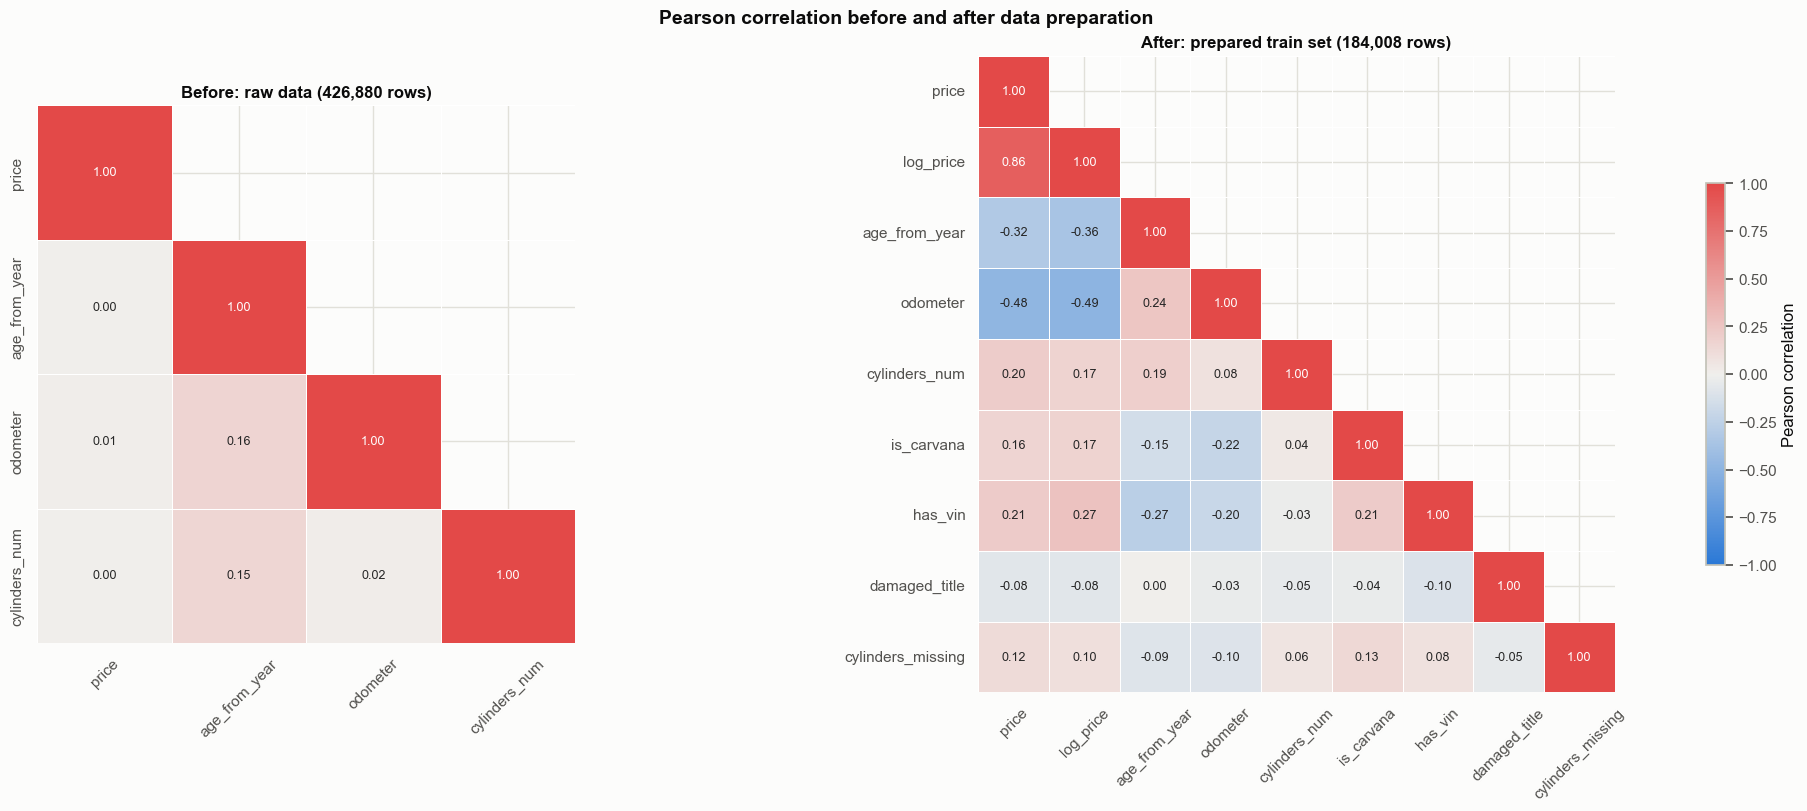

,before: vs price,after: vs price,after: vs log_price
age_from_year,0.01,-0.32,-0.36
odometer,0.01,-0.48,-0.49
cylinders_num,0.00,0.20,0.17


age vs odometer: before +0.157 | after +0.244
flags vs log_price: {'is_carvana': 0.169, 'has_vin': 0.267, 'damaged_title': -0.077, 'cylinders_missing': 0.1}


In [ ]:
#Correlation before vs after preparation
# Pearson is used on purpose: it is sensitive to outliers and skew, so it shows what the cleaning changed.
before_cols = [TARGET, "age_from_year", "odometer", "cylinders_num"]
after_cols = [TARGET, "log_price", "age_from_year", "odometer", "cylinders_num",
              "is_carvana", "has_vin", "damaged_title", "cylinders_missing"]
cm_before = df[before_cols].corr()
cm_after = trees_train[after_cols].corr()

fig, ax = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1, 1.9]}, layout="constrained")
for a, cm, title in [(ax[0], cm_before, f"Before: raw data ({len(df):,} rows)"),
                     (ax[1], cm_after, f"After: prepared train set ({len(trees_train):,} rows)")]:
    sns.heatmap(cm, mask=np.triu(np.ones_like(cm, dtype=bool), 1), annot=True, fmt=".2f", cmap=DIV, vmin=-1, vmax=1,
                center=0, square=True, linewidths=.5, cbar=False, ax=a, annot_kws={"size": 9})
    a.set_title(title)
    a.tick_params(axis="x", rotation=45)
fig.colorbar(ax[1].collections[0], ax=ax, shrink=.6, label="Pearson correlation")
fig.suptitle("Pearson correlation before and after data preparation", fontsize=14, fontweight="bold")
plt.show()

feats = ["age_from_year", "odometer", "cylinders_num"]
corr_change = pd.DataFrame({"before: vs price": cm_before.loc[feats, TARGET],
                            "after: vs price": cm_after.loc[feats, TARGET],
                            "after: vs log_price": cm_after.loc[feats, "log_price"]})
display(corr_change.round(3))
print(f"age vs odometer: before {cm_before.loc['age_from_year', 'odometer']:+.3f} | after {cm_after.loc['age_from_year', 'odometer']:+.3f}")
print("flags vs log_price:", cm_after.loc[["is_carvana", "has_vin", "damaged_title", "cylinders_missing"], "log_price"].round(3).to_dict())

In [ ]:
#Final summary of the data preparation
preparation_summary = {
    'start' : ['raw file: 426,880 rows x 26 columns'],
    'rows removed' : ['price outside 500-124,900: 42,475 (placeholder zeros, 1-499 junk prices, typed values up to 3.7 billion)',
                      'year outside 1950-2021 or missing: 2,348',
                      'odometer above 500,000 miles: 1,096',
                      'repeated VIN, most recent ad kept: 131,808 (the same car cross-posted)',
                      'identical content: 19,143',
                      '230,010 rows remain (53.9%); 151k of the 197k removed rows were duplicate ads, not bad data'],
    'fixes' : ['8 electric cars listed as manual set to automatic', '"truck" merged into "pickup"'],
    'columns added' : ['age_from_year and cylinders_num (numeric versions of year and cylinders text)',
                       'model_full = manufacturer + first word of model (4,797 names, e.g. "ford f150")',
                       'flags: is_carvana (3.9% of rows), has_vin (44.5%), damaged_title (4.1%), cylinders_missing',
                       'log_price as the target (price kept for reporting in dollars)'],
    'columns dropped' : ['id, url, region_url, image_url, county, region, lat, long, VIN, description',
                         'posting_date with its month and weekday, year, cylinders text, raw model'],
    'missing values' : ['categories: "(missing)" as its own level',
                        'odometer: median of cars of the same age, learned on train (1 yr -> 12k, 10 yrs -> 124k miles)',
                        'cylinders: train median (6) plus the cylinders_missing flag'],
    'split' : ['80/20 random split with RANDOM_seed: train 184,008 rows, test 46,002 rows'],
    'tree copy (label encoded)' : ['train 184,008 x 20, test 46,002 x 20',
                                   '11 label-coded categories + 3 numbers + 4 flags + 2 targets (price, log_price)',
                                   'codes learned on train; 547 test cells hold a level unseen in train (code -1)'],
    'linear copy (one-hot)' : ['train 184,008 x 363, test 46,002 x 363',
                               '354 one-hot columns + 3 scaled numbers (mean 0, std 1) + 4 flags + 2 targets',
                               'model kept as the top 200 names; 20.8% of train rows fall into "other"'],
    'files' : ['prepared/trees_train.parquet, prepared/trees_test.parquet',
               'prepared/linear_train.parquet, prepared/linear_test.parquet'],
    'effect on correlations' : ['before, every numeric feature shows about 0 correlation with price (age 0.01, odometer 0.01, cylinders 0.00): a few prices in the billions swamp the measure',
                                'after cleaning the real links appear: odometer -0.48, age -0.32, cylinders +0.20 with price, and similar with log_price (-0.49, -0.36, +0.17)',
                                'age vs odometer rises from 0.16 to 0.24 once the impossible odometer values are gone',
                                'age shows -0.36 here but -0.67 with Spearman: the age-price link is curved (classic cars), which favours tree models or an extra age term for linear models',
                                'the new flags carry signal of their own: has_vin +0.27, is_carvana +0.17, cylinders_missing +0.10, damaged_title -0.08 (small only because 4% of rows are damaged)'],
}